In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    auc
)

from xgboost import XGBClassifier

# 1. CREATE FOLDERS
# ============================================================

os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("LOADING DATASET")
print("============================================================")

file_path = "Customer_Churn_Dataset.xlsx"

df = pd.read_excel(file_path)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

LOADING DATASET
Rows: 3216
Columns: 28


In [2]:

print("DATA INFORMATION")
print("============================================================")

print(df.info())


DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3216 entries, 0 to 3215
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               3216 non-null   object 
 1   Age                       3216 non-null   int64  
 2   Gender                    3216 non-null   object 
 3   City                      3216 non-null   object 
 4   Income_Level              3216 non-null   object 
 5   Tenure_Months             3216 non-null   int64  
 6   Signup_Date               3216 non-null   object 
 7   Contract_Type             3216 non-null   object 
 8   Plan_Type                 3216 non-null   object 
 9   Payment_Method            3216 non-null   object 
 10  Auto_Renewal_Flag         3216 non-null   int64  
 11  Usage_Frequency           3216 non-null   int64  
 12  Days_Since_Last_Activity  3216 non-null   int64  
 13  Feature_Usage_Count       3216 non-null   int6

In [3]:
print("\nFirst 5 rows:")
print(df.head())


First 5 rows:
  Customer_ID  Age  Gender     City Income_Level  Tenure_Months Signup_Date  \
0   CUST00001   38    Male    Delhi         High              7  2026-01-12   
1   CUST00002   32   Other     Pune         High              8  2025-11-27   
2   CUST00003   53   Other  Chennai         High              8  2025-11-26   
3   CUST00004   49  Female     Pune       Medium             37  2023-07-10   
4   CUST00005   49   Other  Kolkata       Medium              9  2025-10-20   

  Contract_Type Plan_Type Payment_Method  ...  Late_Payment_Count  \
0        Annual     Basic            UPI  ...                   2   
1        Annual     Basic     Debit Card  ...                   0   
2       Monthly   Premium         Wallet  ...                   0   
3       Prepaid     Basic         Wallet  ...                   1   
4       Monthly  Standard    Net Banking  ...                   1   

   Support_Tickets_Raised  Complaint_Count  Avg_Resolution_Time_Hrs  \
0                       

In [4]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Customer_ID                 0
Age                         0
Gender                      0
City                        0
Income_Level                0
Tenure_Months               0
Signup_Date                 0
Contract_Type               0
Plan_Type                   0
Payment_Method              0
Auto_Renewal_Flag           0
Usage_Frequency             0
Days_Since_Last_Activity    0
Feature_Usage_Count         0
Avg_Session_Duration_Min    0
Monthly_Charges             0
Total_Charges               0
Discount_Applied_Pct        0
Late_Payment_Count          0
Support_Tickets_Raised      0
Complaint_Count             0
Avg_Resolution_Time_Hrs     0
Satisfaction_Score          0
Referral_Count              0
Loyalty_Program_Member      0
Upsell_Downgrade_History    0
Email_Open_Rate_Pct         0
Churn_Flag                  0
dtype: int64


In [5]:
print("COLUMN NAMES")
print("=" * 60)

print(df.columns.tolist())

COLUMN NAMES
['Customer_ID', 'Age', 'Gender', 'City', 'Income_Level', 'Tenure_Months', 'Signup_Date', 'Contract_Type', 'Plan_Type', 'Payment_Method', 'Auto_Renewal_Flag', 'Usage_Frequency', 'Days_Since_Last_Activity', 'Feature_Usage_Count', 'Avg_Session_Duration_Min', 'Monthly_Charges', 'Total_Charges', 'Discount_Applied_Pct', 'Late_Payment_Count', 'Support_Tickets_Raised', 'Complaint_Count', 'Avg_Resolution_Time_Hrs', 'Satisfaction_Score', 'Referral_Count', 'Loyalty_Program_Member', 'Upsell_Downgrade_History', 'Email_Open_Rate_Pct', 'Churn_Flag']


In [6]:
print("DUPLICATE CHECK")
print("=" * 60)

duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

if duplicate_count > 0:

    df = df.drop_duplicates()

    print("Duplicate rows removed.")

else:

    print("No duplicate rows found.")



DUPLICATE CHECK
Duplicate rows: 0
No duplicate rows found.


In [7]:
#  CHECK CUSTOMER ID DUPLICATES
# ============================================================

if "Customer_ID" in df.columns:

    customer_id_duplicates = df["Customer_ID"].duplicated().sum()

    print("\nDuplicate Customer_ID:", customer_id_duplicates)



Duplicate Customer_ID: 0


In [8]:
#CHECK DATA TYPES
# ============================================================

print("\n" + "=" * 60)
print("DATA TYPES")
print("=" * 60)

print(df.dtypes)



DATA TYPES
Customer_ID                  object
Age                           int64
Gender                       object
City                         object
Income_Level                 object
Tenure_Months                 int64
Signup_Date                  object
Contract_Type                object
Plan_Type                    object
Payment_Method               object
Auto_Renewal_Flag             int64
Usage_Frequency               int64
Days_Since_Last_Activity      int64
Feature_Usage_Count           int64
Avg_Session_Duration_Min    float64
Monthly_Charges             float64
Total_Charges               float64
Discount_Applied_Pct          int64
Late_Payment_Count            int64
Support_Tickets_Raised        int64
Complaint_Count               int64
Avg_Resolution_Time_Hrs     float64
Satisfaction_Score            int64
Referral_Count                int64
Loyalty_Program_Member        int64
Upsell_Downgrade_History     object
Email_Open_Rate_Pct         float64
Churn_Flag      

In [9]:
#REMOVE UNWANTED COLUMN
# ============================================================

print("\n" + "=" * 60)
print("REMOVING UNWANTED COLUMNS")
print("=" * 60)

if "Customer_ID" in df.columns:

    df.drop(
        columns=["Customer_ID"],
        inplace=True
    )

    print("Removed: Customer_ID")



REMOVING UNWANTED COLUMNS
Removed: Customer_ID


In [10]:
print("DATE PROCESSING")
print("=" * 60)

if "Signup_Date" in df.columns:

    df["Signup_Date"] = pd.to_datetime(
        df["Signup_Date"],
        errors="coerce"
    )

    print("Signup_Date converted to datetime.")

DATE PROCESSING
Signup_Date converted to datetime.


In [11]:
# 10. CREATE DATE FEATURES
# ============================================================

if "Signup_Date" in df.columns:

    df["Signup_Year"] = (
        df["Signup_Date"].dt.year
    )

    df["Signup_Month"] = (
        df["Signup_Date"].dt.month
    )

    df["Signup_Quarter"] = (
        df["Signup_Date"].dt.quarter
    )

    df["Signup_DayOfWeek"] = (
        df["Signup_Date"].dt.dayofweek
    )

    print("\nCreated date features:")

    print("Signup_Year")
    print("Signup_Month")
    print("Signup_Quarter")
    print("Signup_DayOfWeek")


Created date features:
Signup_Year
Signup_Month
Signup_Quarter
Signup_DayOfWeek


In [12]:
# 11. REMOVE ORIGINAL DATE COLUMN
# ============================================================

if "Signup_Date" in df.columns:

    df.drop(
        columns=["Signup_Date"],
        inplace=True
    )

    print("\nRemoved original Signup_Date column.")


Removed original Signup_Date column.


In [13]:
# 12. CHECK INVALID VALUES
# ============================================================

print("\n" + "=" * 60)
print("INVALID VALUE CHECK")
print("=" * 60)


# Age
if "Age" in df.columns:

    print(
        "Invalid Age:",
        (df["Age"] <= 0).sum()
    )


# Tenure
if "Tenure_Months" in df.columns:

    print(
        "Invalid Tenure:",
        (df["Tenure_Months"] < 0).sum()
    )


# Monthly charges
if "Monthly_Charges" in df.columns:

    print(
        "Invalid Monthly Charges:",
        (df["Monthly_Charges"] < 0).sum()
    )


# Total charges
if "Total_Charges" in df.columns:

    print(
        "Invalid Total Charges:",
        (df["Total_Charges"] < 0).sum()
    )


# Satisfaction
"""if "Satisfaction_Score" in df.columns:

    print(
        "Invalid Satisfaction Score:",
        (
            (df["Satisfaction_Score"] < 1) |
            (df["Satisfaction_Score"] > 5)
        ).sum()
    )
      print(
        "Invalid Satisfaction Score:",
        invalid_satisfaction.sum()
    )

    print("\nInvalid Satisfaction Score values:")
    print(
        df.loc[
            invalid_satisfaction,
            "Satisfaction_Score"
        ].value_counts().sort_index()
    )"""
# ============================================================
# SATISFACTION SCORE VALIDATION
# ============================================================

if "Satisfaction_Score" in df.columns:

    invalid_satisfaction = (
        (df["Satisfaction_Score"] < 1) |
        (df["Satisfaction_Score"] > 10)
    )

    print(
        "Invalid Satisfaction Score:",
        invalid_satisfaction.sum()
    )

    print("\nSatisfaction Score Distribution:")

    print(
        df["Satisfaction_Score"]
        .value_counts(dropna=False)
        .sort_index()
    )


INVALID VALUE CHECK
Invalid Age: 0
Invalid Tenure: 0
Invalid Monthly Charges: 0
Invalid Total Charges: 0
Invalid Satisfaction Score: 0

Satisfaction Score Distribution:
Satisfaction_Score
1     399
2     336
3     349
4     320
5     319
6     364
7     348
8     317
9     250
10    214
Name: count, dtype: int64


In [14]:
 #13. CHECK FINAL DATASET
# ============================================================

print("\n" + "=" * 60)
print("FINAL CLEANED DATASET")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nFinal columns:")

for column in df.columns:

    print(column)



FINAL CLEANED DATASET
Rows: 3216
Columns: 30

Final columns:
Age
Gender
City
Income_Level
Tenure_Months
Contract_Type
Plan_Type
Payment_Method
Auto_Renewal_Flag
Usage_Frequency
Days_Since_Last_Activity
Feature_Usage_Count
Avg_Session_Duration_Min
Monthly_Charges
Total_Charges
Discount_Applied_Pct
Late_Payment_Count
Support_Tickets_Raised
Complaint_Count
Avg_Resolution_Time_Hrs
Satisfaction_Score
Referral_Count
Loyalty_Program_Member
Upsell_Downgrade_History
Email_Open_Rate_Pct
Churn_Flag
Signup_Year
Signup_Month
Signup_Quarter
Signup_DayOfWeek


In [15]:
# ============================================================
# 16. TARGET DISTRIBUTION
# ============================================================

print("\n========== CHURN DISTRIBUTION ==========")

churn_counts = df["Churn_Flag"].value_counts()

print("Non-Churn (0):",
      churn_counts.get(0, 0))

print("Churn (1):",
      churn_counts.get(1, 0))

print("\nPercentage:")
print(
    df["Churn_Flag"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


========== CHURN DISTRIBUTION ==========
Non-Churn (0): 2699
Churn (1): 517

Percentage:
Churn_Flag
0    83.92
1    16.08
Name: proportion, dtype: float64


In [16]:
# ============================================================
# 17. IDENTIFY NUMERICAL FEATURES FOR EDA
# ============================================================

numerical_columns_eda = df.select_dtypes(
    include=np.number
).columns.tolist()

numerical_columns_eda.remove("Churn_Flag")

print("Numerical columns:")
print(numerical_columns_eda)

Numerical columns:
['Age', 'Tenure_Months', 'Auto_Renewal_Flag', 'Usage_Frequency', 'Days_Since_Last_Activity', 'Feature_Usage_Count', 'Avg_Session_Duration_Min', 'Monthly_Charges', 'Total_Charges', 'Discount_Applied_Pct', 'Late_Payment_Count', 'Support_Tickets_Raised', 'Complaint_Count', 'Avg_Resolution_Time_Hrs', 'Satisfaction_Score', 'Referral_Count', 'Loyalty_Program_Member', 'Email_Open_Rate_Pct', 'Signup_Year', 'Signup_Month', 'Signup_Quarter', 'Signup_DayOfWeek']


In [17]:
# ============================================================
# 18. CHURN VS NUMERICAL FEATURES
# ============================================================

churn_analysis = (
    df.groupby("Churn_Flag")[numerical_columns_eda]
    .mean()
    .T
)

display(churn_analysis.round(2))

Churn_Flag,0,1
Age,43.67,43.69
Tenure_Months,36.81,33.04
Auto_Renewal_Flag,0.60,0.62
Usage_Frequency,14.12,13.39
Days_Since_Last_Activity,89.57,109.24
Feature_Usage_Count,9.42,10.07
Avg_Session_Duration_Min,11.90,11.88
Monthly_Charges,1578.71,1493.78
Total_Charges,58477.54,49222.24
Discount_Applied_Pct,8.10,7.91


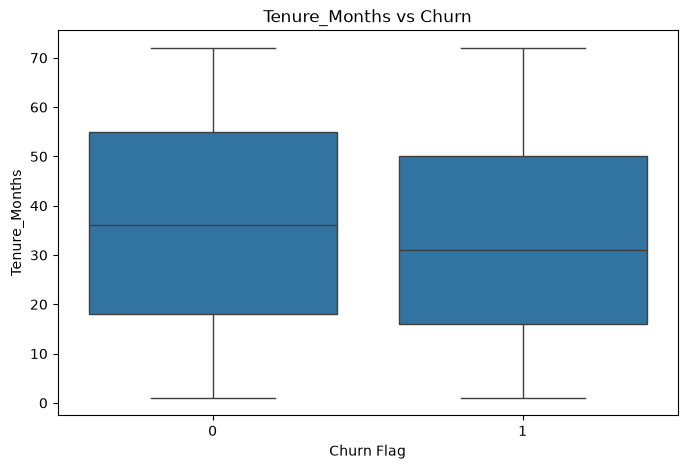

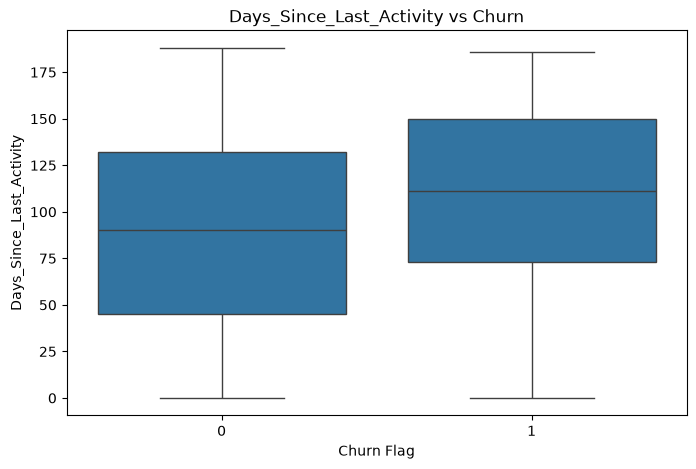

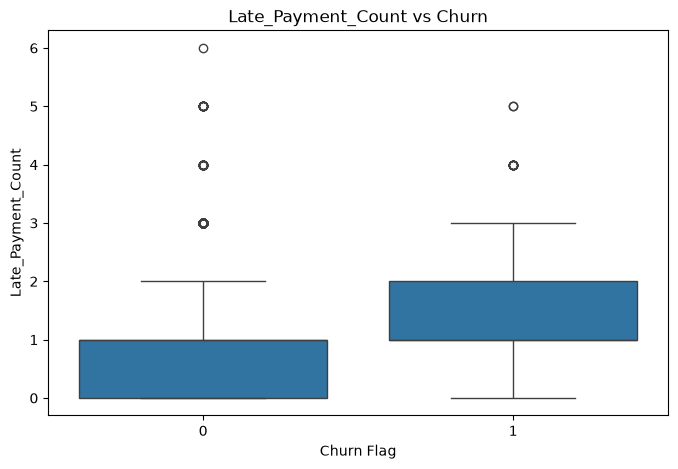

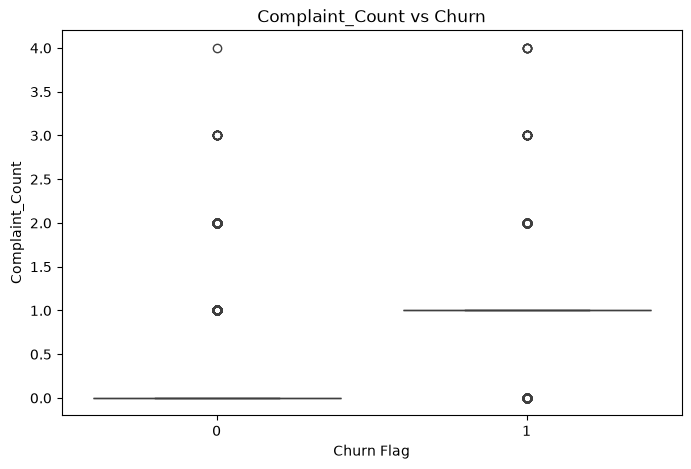

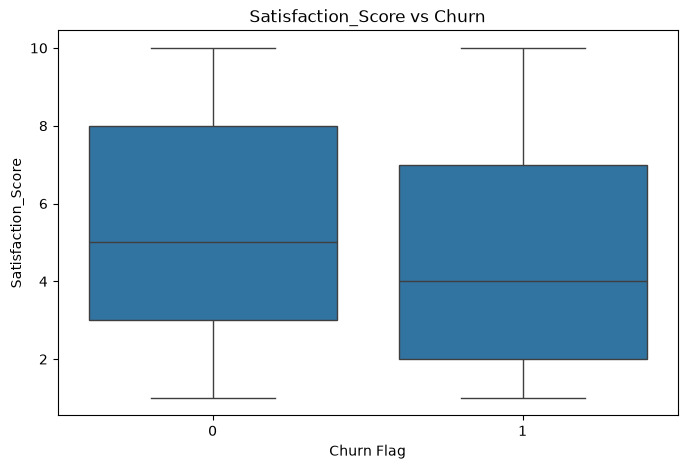

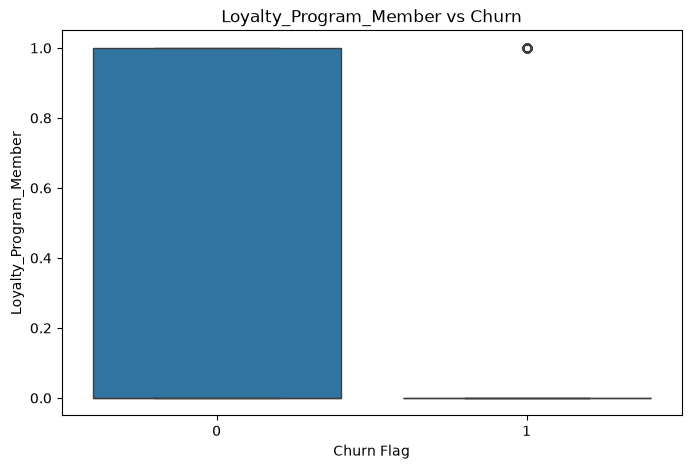

In [18]:
# ============================================================
# 19. NUMERICAL FEATURE BOXPLOTS
# ============================================================

features_to_plot = [
    "Tenure_Months",
    "Days_Since_Last_Activity",
    "Late_Payment_Count",
    "Complaint_Count",
    "Satisfaction_Score",
    "Loyalty_Program_Member"
]

for feature in features_to_plot:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="Churn_Flag",
        y=feature
    )

    plt.title(f"{feature} vs Churn")
    plt.xlabel("Churn Flag")
    plt.ylabel(feature)

    plt.show()

In [19]:
# ============================================================
# 20. IDENTIFY CATEGORICAL FEATURES
# ============================================================

categorical_columns_eda = df.select_dtypes(
    include="object"
).columns.tolist()

print("Categorical columns:")
print(categorical_columns_eda)

Categorical columns:
['Gender', 'City', 'Income_Level', 'Contract_Type', 'Plan_Type', 'Payment_Method', 'Upsell_Downgrade_History']


In [20]:
# ============================================================
# 21. CHURN RATE BY CATEGORICAL FEATURES
# ============================================================

for column in categorical_columns_eda:

    churn_rate = (
        df.groupby(column)["Churn_Flag"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print("\n" + "=" * 50)
    print(column)
    print("=" * 50)

    display(churn_rate.round(2))


Gender


Gender
Male      17.66
Female    16.36
Other     14.27
Name: Churn_Flag, dtype: float64


City


City
Kolkata      19.27
Bengaluru    17.77
Chennai      16.95
Hyderabad    15.45
Mumbai       14.94
Pune         14.35
Delhi        13.62
Name: Churn_Flag, dtype: float64


Income_Level


...

Plan_Type
Premium     17.03
Basic       16.03
Standard    15.28
Name: Churn_Flag, dtype: float64


Payment_Method


Payment_Method
Wallet         19.35
Credit Card    16.30
Debit Card     16.19
UPI            14.73
Net Banking    13.73
Name: Churn_Flag, dtype: float64


Upsell_Downgrade_History


Upsell_Downgrade_History
Upgraded      16.91
No History    15.88
Downgraded    15.88
Name: Churn_Flag, dtype: float64

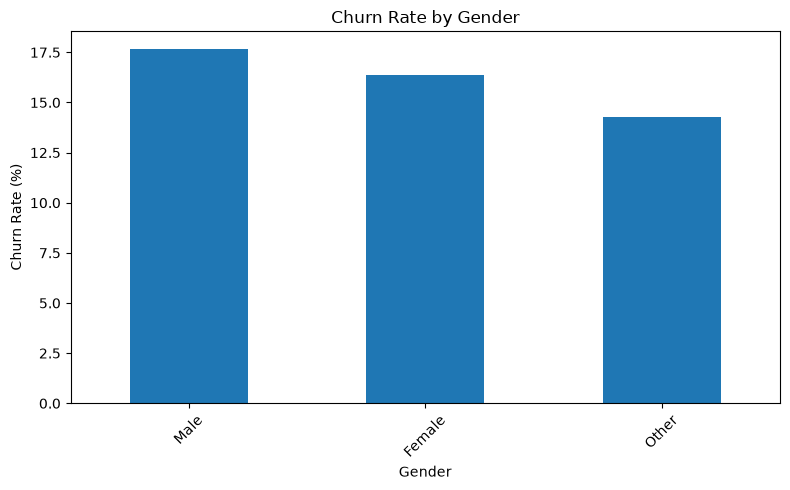

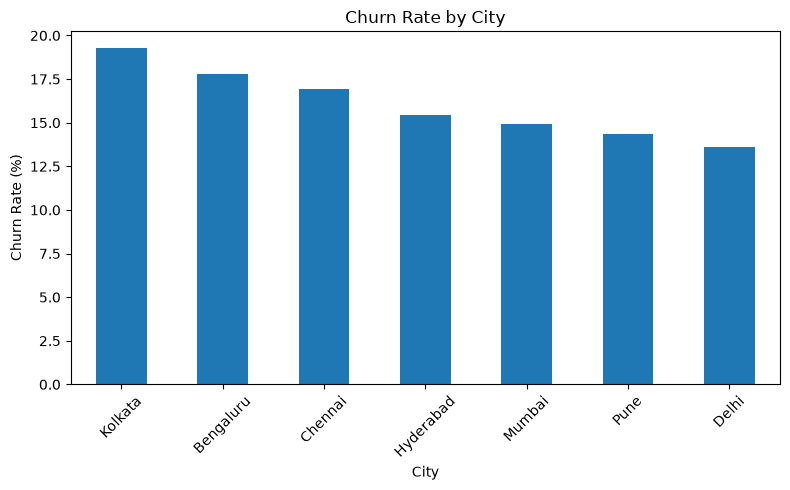

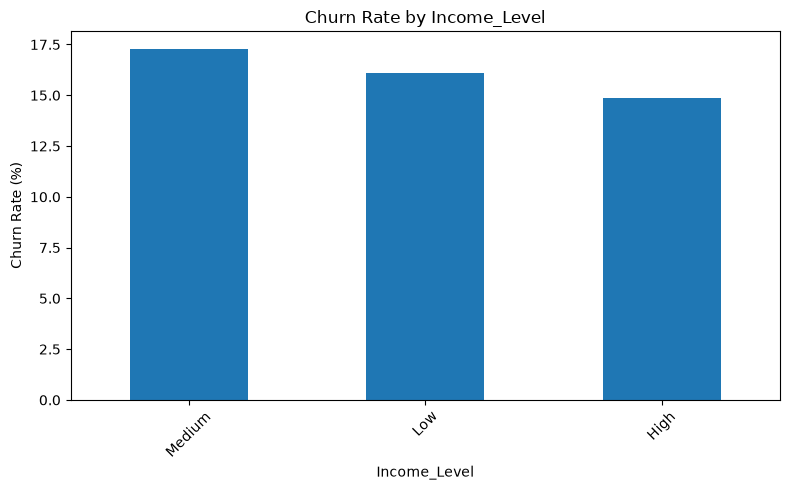

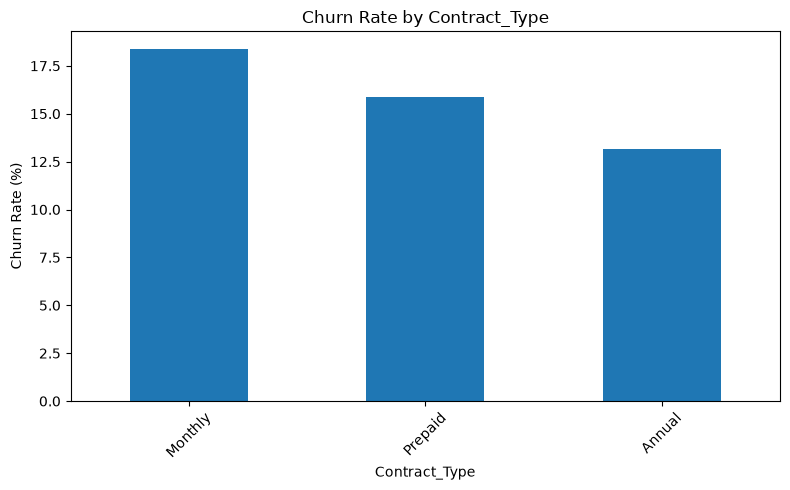

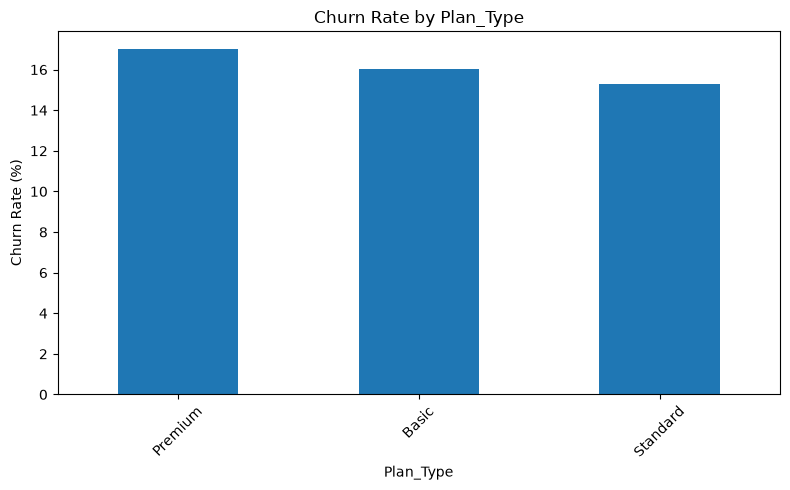

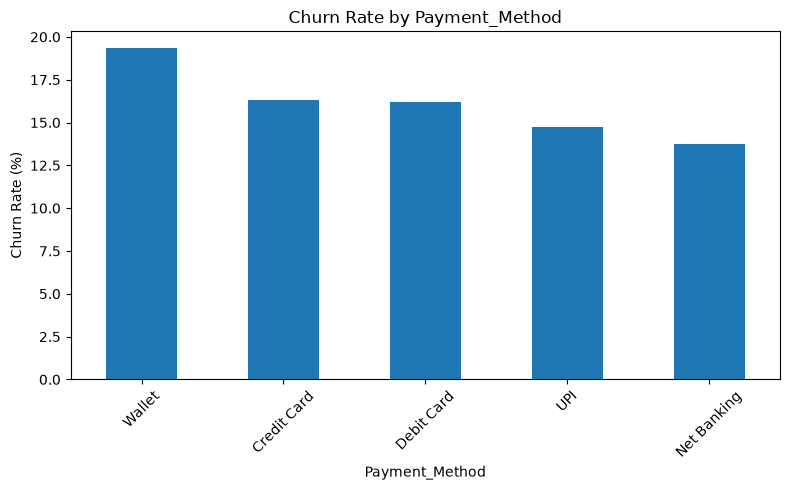

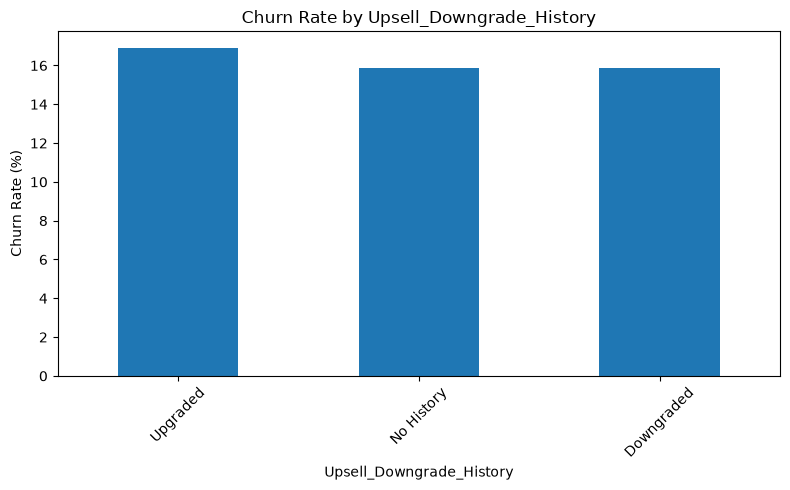

In [21]:
# ============================================================
# 22. CATEGORICAL CHURN RATE VISUALIZATION
# ============================================================

for column in categorical_columns_eda:

    churn_rate = (
        df.groupby(column)["Churn_Flag"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 5))

    churn_rate.plot(kind="bar")

    plt.title(f"Churn Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Churn Rate (%)")

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

In [22]:
# ============================================================
# 23. CORRELATION WITH CHURN
# ============================================================

correlation = (
    df[numerical_columns_eda + ["Churn_Flag"]]
    .corr()["Churn_Flag"]
    .drop("Churn_Flag")
    .sort_values(ascending=False)
)

print("\n========== CORRELATION WITH CHURN ==========")

display(correlation.round(3))


========== CORRELATION WITH CHURN ==========


Complaint_Count             0.432
Late_Payment_Count          0.156
Days_Since_Last_Activity    0.140
Signup_Year                 0.059
Feature_Usage_Count         0.040
Signup_DayOfWeek            0.035
Support_Tickets_Raised      0.028
Auto_Renewal_Flag           0.016
Signup_Quarter              0.004
Signup_Month                0.002
Age                         0.000
Avg_Session_Duration_Min   -0.001
Discount_Applied_Pct       -0.009
Avg_Resolution_Time_Hrs    -0.009
Referral_Count             -0.013
Email_Open_Rate_Pct        -0.016
Usage_Frequency            -0.035
Monthly_Charges            -0.039
Tenure_Months              -0.065
Total_Charges              -0.072
Satisfaction_Score         -0.090
Loyalty_Program_Member     -0.158
Name: Churn_Flag, dtype: float64

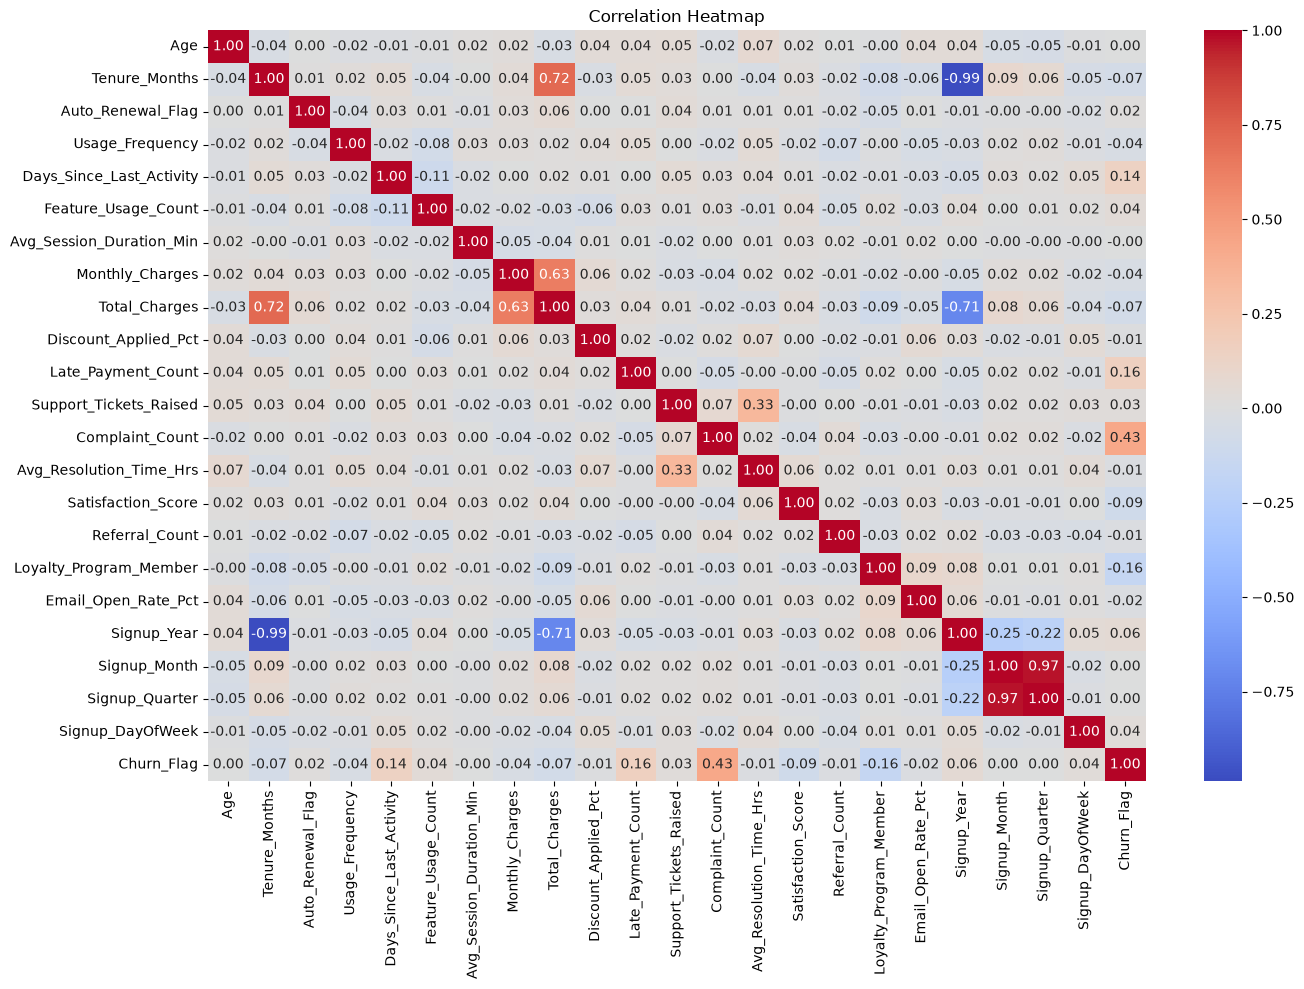

In [23]:
# ============================================================
# 24. CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(14, 10))

sns.heatmap(
    df[numerical_columns_eda + ["Churn_Flag"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# 25. FEATURE ENGINEERING
# ============================================================

print("\n" + "=" * 60)
print("FEATURE ENGINEERING")
print("=" * 60)

# 1. Average Monthly Total Charges
df["Avg_Monthly_Total_Charges"] = (
    df["Total_Charges"] /
    df["Tenure_Months"].replace(0, 1)
)

# 2. Charge Ratio
df["Charge_Ratio"] = (
    df["Monthly_Charges"] /
    df["Avg_Monthly_Total_Charges"].replace(0, 1)
)

# 3. Activity Risk
df["Activity_Risk"] = (
    df["Days_Since_Last_Activity"] /
    df["Tenure_Months"].replace(0, 1)
)

# 4. Service Issue Score
df["Service_Issue_Score"] = (
    df["Complaint_Count"] +
    df["Support_Tickets_Raised"]
)

new_features = [
    "Avg_Monthly_Total_Charges",
    "Charge_Ratio",
    "Activity_Risk",
    "Service_Issue_Score"
]

print("\nNew Features Created:")
print(new_features)

print("\nSample:")
display(df[new_features].head())


FEATURE ENGINEERING

New Features Created:
['Avg_Monthly_Total_Charges', 'Charge_Ratio', 'Activity_Risk', 'Service_Issue_Score']

Sample:


,Avg_Monthly_Total_Charges,Charge_Ratio,Activity_Risk,Service_Issue_Score
0,293.364286,1.036220,18.428571,0
1,1346.652500,1.019261,4.250000,1
2,1779.695000,1.033082,10.000000,2
3,2708.826486,1.038147,2.351351,2
4,2125.943333,1.056590,1.777778,3


In [25]:
# ============================================================
# 26. ENGINEERED FEATURES VS CHURN
# ============================================================

engineered_churn_analysis = (
    df.groupby("Churn_Flag")[new_features]
    .mean()
    .T
)

print("\n========== ENGINEERED FEATURES VS CHURN ==========")

display(engineered_churn_analysis.round(2))


========== ENGINEERED FEATURES VS CHURN ==========


Churn_Flag,0,1
Avg_Monthly_Total_Charges,1568.82,1476.08
Charge_Ratio,1.01,1.01
Activity_Risk,6.79,10.08
Service_Issue_Score,1.76,2.63


In [26]:
# ============================================================
# 27. SEPARATE FEATURES AND TARGET
# ============================================================

X = df.drop(columns=["Churn_Flag"])
y = df["Churn_Flag"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3216, 33)
y shape: (3216,)


In [27]:
# ============================================================
# 28. IDENTIFY FINAL FEATURE TYPES
# ============================================================

numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X.select_dtypes(
    include="object"
).columns.tolist()

print("\n========== NUMERICAL COLUMNS ==========")
print(numerical_columns)

print("\n========== CATEGORICAL COLUMNS ==========")
print(categorical_columns)

print("\nNumber of numerical features:",
      len(numerical_columns))

print("Number of categorical features:",
      len(categorical_columns))


========== NUMERICAL COLUMNS ==========
['Age', 'Tenure_Months', 'Auto_Renewal_Flag', 'Usage_Frequency', 'Days_Since_Last_Activity', 'Feature_Usage_Count', 'Avg_Session_Duration_Min', 'Monthly_Charges', 'Total_Charges', 'Discount_Applied_Pct', 'Late_Payment_Count', 'Support_Tickets_Raised', 'Complaint_Count', 'Avg_Resolution_Time_Hrs', 'Satisfaction_Score', 'Referral_Count', 'Loyalty_Program_Member', 'Email_Open_Rate_Pct', 'Signup_Year', 'Signup_Month', 'Signup_Quarter', 'Signup_DayOfWeek', 'Avg_Monthly_Total_Charges', 'Charge_Ratio', 'Activity_Risk', 'Service_Issue_Score']

========== CATEGORICAL COLUMNS ==========
['Gender', 'City', 'Income_Level', 'Contract_Type', 'Plan_Type', 'Payment_Method', 'Upsell_Downgrade_History']

Number of numerical features: 26
Number of categorical features: 7


In [28]:
# ============================================================
# 29. TRAIN TEST SPLIT
# ============================================================

"""X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)"""
# ============================================================
# TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# First: separate 20% for final testing
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second: split remaining 80% into
# 60% Training and 20% Validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("=" * 60)
print("TRAIN / VALIDATION / TEST SPLIT")
print("=" * 60)


print("Training rows   :", len(X_train))
print("Validation rows :", len(X_val))
print("Test rows       :", len(X_test))

print("\nTraining percentage   :", round(len(X_train) / len(X) * 100, 2), "%")
print("Validation percentage :", round(len(X_val) / len(X) * 100, 2), "%")
print("Test percentage       :", round(len(X_test) / len(X) * 100, 2), "%")

TRAIN / VALIDATION / TEST SPLIT
Training rows   : 1929
Validation rows : 643
Test rows       : 644

Training percentage   : 59.98 %
Validation percentage : 19.99 %
Test percentage       : 20.02 %


In [29]:
# ============================================================
# 30. NUMERICAL PREPROCESSING
# ============================================================

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical preprocessing created.")

Numerical preprocessing created.


In [30]:
# ============================================================
# 31. CATEGORICAL PREPROCESSING
# ============================================================

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

print("Categorical preprocessing created.")

Categorical preprocessing created.


In [31]:
# ============================================================
# 32. COMBINE PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numeric_pipeline,
            numerical_columns
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_columns
        )
    ]
)

print("Preprocessor created.")

Preprocessor created.


In [32]:
# ============================================================
# 33. APPLY PREPROCESSING
# ============================================================

"""X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:",
      X_train_processed.shape)

print("X_test_processed shape:",
      X_test_processed.shape)"""
# ============================================================
# PREPROCESSING
# ============================================================

# Fit preprocessing ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the already-fitted preprocessing
# to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training shape   :", X_train_processed.shape)
print("Validation shape :", X_val_processed.shape)
print("Test shape       :", X_test_processed.shape)

Training shape   : (1929, 53)
Validation shape : (643, 53)
Test shape       : (644, 53)


In [33]:
# ============================================================
# LOGISTIC REGRESSION MODEL
# ============================================================

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [34]:
# ============================================================
# LOGISTIC REGRESSION - EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Make predictions on test data
y_pred_logistic = logistic_model.predict(X_test_processed)

# Get probability of churn (class 1)
y_prob_logistic = logistic_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)
roc_auc = roc_auc_score(y_test, y_prob_logistic)

# Display results
print("========== LOGISTIC REGRESSION RESULTS ==========")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_test, y_pred_logistic))

========== LOGISTIC REGRESSION RESULTS ==========
Accuracy  : 0.8339
Precision : 0.4908
Recall    : 0.7692
F1 Score  : 0.5993
ROC-AUC   : 0.8810

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.95      0.85      0.90       540
           1       0.49      0.77      0.60       104

    accuracy                           0.83       644
   macro avg       0.72      0.81      0.75       644
weighted avg       0.88      0.83      0.85       644



In [35]:
# ============================================================
# LOGISTIC REGRESSION - COMPLETE EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

"""# Make predictions
y_pred_logistic = logistic_model.predict(X_test_processed)

# Get probability of Churn = 1
y_prob_logistic = logistic_model.predict_proba(X_test_processed)[:, 1]

# Calculate metrics
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
precision_logistic = precision_score(y_test, y_pred_logistic)
recall_logistic = recall_score(y_test, y_pred_logistic)
f1_logistic = f1_score(y_test, y_pred_logistic)
roc_auc_logistic = roc_auc_score(y_test, y_prob_logistic)

# PR-AUC
pr_auc_logistic = average_precision_score(y_test, y_prob_logistic)

# Confusion Matrix
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

# Display results
print("========== LOGISTIC REGRESSION RESULTS ==========")
print(f"Accuracy  : {accuracy_logistic:.4f}")
print(f"Precision : {precision_logistic:.4f}")
print(f"Recall    : {recall_logistic:.4f}")
print(f"F1 Score  : {f1_logistic:.4f}")
print(f"ROC-AUC   : {roc_auc_logistic:.4f}")
print(f"PR-AUC    : {pr_auc_logistic:.4f}")

print("\n========== CONFUSION MATRIX ==========")
print(cm_logistic)

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_test, y_pred_logistic))"""
# ============================================================
# LOGISTIC REGRESSION - VALIDATION EVALUATION
# ============================================================

y_pred_logistic = logistic_model.predict(X_val_processed)

y_prob_logistic = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

accuracy_logistic = accuracy_score(
    y_val, y_pred_logistic
)

precision_logistic = precision_score(
    y_val,
    y_pred_logistic,
    zero_division=0
)

recall_logistic = recall_score(
    y_val,
    y_pred_logistic,
    zero_division=0
)

f1_logistic = f1_score(
    y_val,
    y_pred_logistic,
    zero_division=0
)

roc_auc_logistic = roc_auc_score(
    y_val,
    y_prob_logistic
)

pr_auc_logistic = average_precision_score(
    y_val,
    y_prob_logistic
)

cm_logistic = confusion_matrix(
    y_val,
    y_pred_logistic,
    labels=[0, 1]
)

print("========== LOGISTIC REGRESSION - VALIDATION ==========")
print(f"Accuracy  : {accuracy_logistic:.4f}")
print(f"Precision : {precision_logistic:.4f}")
print(f"Recall    : {recall_logistic:.4f}")
print(f"F1 Score  : {f1_logistic:.4f}")
print(f"ROC-AUC   : {roc_auc_logistic:.4f}")
print(f"PR-AUC    : {pr_auc_logistic:.4f}")

print("\n========== CONFUSION MATRIX ==========")
print(cm_logistic)
print("\n========== CLASSIFICATION REPORT ==========")
print(
    classification_report(
        y_val,
        y_pred_logistic,
        zero_division=0
    )
)

========== LOGISTIC REGRESSION - VALIDATION ==========
Accuracy  : 0.7885
Precision : 0.4088
Recall    : 0.7184
F1 Score  : 0.5211
ROC-AUC   : 0.8175
PR-AUC    : 0.5209

========== CONFUSION MATRIX ==========
[[433 107]
 [ 29  74]]

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.94      0.80      0.86       540
           1       0.41      0.72      0.52       103

    accuracy                           0.79       643
   macro avg       0.67      0.76      0.69       643
weighted avg       0.85      0.79      0.81       643



In [36]:
# ============================================================
# RANDOM FOREST MODEL
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [37]:
# ============================================================
# RANDOM FOREST - EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

"""# Make predictions on test data
y_pred_rf = rf_model.predict(X_test_processed)

# Get probability of churn (class 1)
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

# Display results
print("========== RANDOM FOREST RESULTS ==========")
print(f"Accuracy  : {accuracy_rf:.4f}")
print(f"Precision : {precision_rf:.4f}")
print(f"Recall    : {recall_rf:.4f}")
print(f"F1 Score  : {f1_rf:.4f}")
print(f"ROC-AUC   : {roc_auc_rf:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_test, y_pred_rf))"""

# ============================================================
# RANDOM FOREST - VALIDATION EVALUATION
# ============================================================

# Make predictions on VALIDATION data
y_pred_rf = rf_model.predict(X_val_processed)

# Get probability of Churn = 1
y_prob_rf = rf_model.predict_proba(
    X_val_processed
)[:, 1]


# ============================================================
# CALCULATE METRICS
# ============================================================

accuracy_rf = accuracy_score(
    y_val,
    y_pred_rf
)

precision_rf = precision_score(
    y_val,
    y_pred_rf,
    zero_division=0
)

recall_rf = recall_score(
    y_val,
    y_pred_rf,
    zero_division=0
)

f1_rf = f1_score(
    y_val,
    y_pred_rf,
    zero_division=0
)

roc_auc_rf = roc_auc_score(
    y_val,
    y_prob_rf
)

pr_auc_rf = average_precision_score(
    y_val,
    y_prob_rf
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm_rf = confusion_matrix(
    y_val,
    y_pred_rf,
    labels=[0, 1]
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("========== RANDOM FOREST - VALIDATION ==========")

print(f"Accuracy  : {accuracy_rf:.4f}")
print(f"Precision : {precision_rf:.4f}")
print(f"Recall    : {recall_rf:.4f}")
print(f"F1 Score  : {f1_rf:.4f}")
print(f"ROC-AUC   : {roc_auc_rf:.4f}")
print(f"PR-AUC    : {pr_auc_rf:.4f}")


print("\n========== CONFUSION MATRIX ==========")
print(cm_rf)


print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_val,
        y_pred_rf,
        zero_division=0
    )
)

========== RANDOM FOREST - VALIDATION ==========
Accuracy  : 0.9082
Precision : 0.7683
Recall    : 0.6117
F1 Score  : 0.6811
ROC-AUC   : 0.9110
PR-AUC    : 0.7282

========== CONFUSION MATRIX ==========
[[521  19]
 [ 40  63]]

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.93      0.96      0.95       540
           1       0.77      0.61      0.68       103

    accuracy                           0.91       643
   macro avg       0.85      0.79      0.81       643
weighted avg       0.90      0.91      0.90       643



In [38]:
# ============================================================
# CHECK TARGET AND FEATURES
# ============================================================

print("Target column:", y.name)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Target column: Churn_Flag

Features:
['Age', 'Gender', 'City', 'Income_Level', 'Tenure_Months', 'Contract_Type', 'Plan_Type', 'Payment_Method', 'Auto_Renewal_Flag', 'Usage_Frequency', 'Days_Since_Last_Activity', 'Feature_Usage_Count', 'Avg_Session_Duration_Min', 'Monthly_Charges', 'Total_Charges', 'Discount_Applied_Pct', 'Late_Payment_Count', 'Support_Tickets_Raised', 'Complaint_Count', 'Avg_Resolution_Time_Hrs', 'Satisfaction_Score', 'Referral_Count', 'Loyalty_Program_Member', 'Upsell_Downgrade_History', 'Email_Open_Rate_Pct', 'Signup_Year', 'Signup_Month', 'Signup_Quarter', 'Signup_DayOfWeek', 'Avg_Monthly_Total_Charges', 'Charge_Ratio', 'Activity_Risk', 'Service_Issue_Score']

Target distribution:
Churn_Flag
0    2699
1     517
Name: count, dtype: int64


In [39]:
# ============================================================
# CHECK WHETHER TARGET IS PRESENT IN FEATURES
# ============================================================

target_in_features = [
    col
    for col in X.columns
    if col.lower() == y.name.lower()
]

print("Target-like columns found in X:", target_in_features)

Target-like columns found in X: []


In [40]:
# ============================================================
# CHECK ENGINEERED FEATURES
# ============================================================

engineered_features = [
    "Avg_Monthly_Total_Charges",
    "Charge_Ratio",
    "Activity_Risk",
    "Service_Issue_Score"
]

print("Engineered features found:\n")

for col in engineered_features:

    if col in X.columns:

        print(
            f"{col}: "
            f"Min = {X[col].min():.4f}, "
            f"Max = {X[col].max():.4f}, "
            f"Mean = {X[col].mean():.4f}"
        )

Engineered features found:

Avg_Monthly_Total_Charges: Min = 188.5171, Max = 3073.0403, Mean = 1553.9116
Charge_Ratio: Min = 0.9524, Max = 1.1109, Mean = 1.0078
Activity_Risk: Min = 0.0000, Max = 186.0000, Mean = 7.3184
Service_Issue_Score: Min = 0.0000, Max = 8.0000, Mean = 1.8974


In [41]:
# ============================================================
# CHECK RELATIONSHIP BETWEEN ENGINEERED FEATURES AND TARGET
# ============================================================

for col in engineered_features:

    if col in df.columns:

        print("\n" + "=" * 60)
        print(col)
        print("=" * 60)

        print(
            df.groupby("Churn_Flag")[col].agg(
                ["min", "max", "mean", "median"]
            )
        )


Avg_Monthly_Total_Charges
                   min         max         mean       median
Churn_Flag                                                  
0           188.517101  3073.04029  1568.820308  1564.813333
1           211.799416  3067.35100  1476.080677  1464.414000

Charge_Ratio
                 min       max      mean  median
Churn_Flag                                      
0           0.952386  1.110926  1.006705     1.0
1           0.954236  1.110799  1.013365     1.0

Activity_Risk
            min    max       mean    median
Churn_Flag                                 
0           0.0  178.0   6.790219  2.500000
1           0.0  186.0  10.075581  3.214286

Service_Issue_Score
            min  max      mean  median
Churn_Flag                            
0             0    8  1.757318     2.0
1             0    8  2.628627     3.0


In [42]:
# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

# Get feature names after preprocessing
feature_names_rf = preprocessor.get_feature_names_out()

# Get feature importance from Random Forest
importance_rf = rf_model.feature_importances_

# Create DataFrame
feature_importance_rf = pd.DataFrame({
    "Feature": feature_names_rf,
    "Importance": importance_rf
})

# Sort by importance
feature_importance_rf = feature_importance_rf.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("========== RANDOM FOREST FEATURE IMPORTANCE ==========")

display(feature_importance_rf)

========== RANDOM FOREST FEATURE IMPORTANCE ==========


,Feature,Importance
0,numerical__Complaint_Count,0.224999
1,numerical__Charge_Ratio,0.069798
2,numerical__Late_Payment_Count,0.058171
3,numerical__Activity_Risk,0.047089
4,numerical__Days_Since_Last_Activity,0.045488
5,numerical__Service_Issue_Score,0.039977
6,numerical__Avg_Resolution_Time_Hrs,0.039439
7,numerical__Total_Charges,0.028909
8,numerical__Avg_Session_Duration_Min,0.028686
9,numerical__Loyalty_Program_Member,0.028406


In [43]:
# ============================================================
# RANDOM FOREST - COMPLETE EVALUATION
# ============================================================

"""from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Make predictions
y_pred_rf = rf_model.predict(X_test_processed)

# Get probability of Churn = 1
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

# Calculate metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

# PR-AUC
pr_auc_rf = average_precision_score(y_test, y_prob_rf)

# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Display results
print("========== RANDOM FOREST RESULTS ==========")
print(f"Accuracy  : {accuracy_rf:.4f}")
print(f"Precision : {precision_rf:.4f}")
print(f"Recall    : {recall_rf:.4f}")
print(f"F1 Score  : {f1_rf:.4f}")
print(f"ROC-AUC   : {roc_auc_rf:.4f}")
print(f"PR-AUC    : {pr_auc_rf:.4f}")

print("\n========== CONFUSION MATRIX ==========")
print(cm_rf)

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_test, y_pred_rf))"""
# ============================================================
# RANDOM FOREST - VALIDATION EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Make predictions on VALIDATION set
y_pred_rf = rf_model.predict(X_val_processed)

# Get probability of Churn = 1
y_prob_rf = rf_model.predict_proba(X_val_processed)[:, 1]

# Calculate metrics
accuracy_rf = accuracy_score(y_val, y_pred_rf)

precision_rf = precision_score(
    y_val,
    y_pred_rf,
    zero_division=0
)

recall_rf = recall_score(
    y_val,
    y_pred_rf,
    zero_division=0
)

f1_rf = f1_score(
    y_val,
    y_pred_rf,
    zero_division=0
)

roc_auc_rf = roc_auc_score(
    y_val,
    y_prob_rf
)

# PR-AUC
pr_auc_rf = average_precision_score(
    y_val,
    y_prob_rf
)

# Confusion Matrix
cm_rf = confusion_matrix(
    y_val,
    y_pred_rf,
    labels=[0, 1]
)

# Display results
print("========== RANDOM FOREST - VALIDATION ==========")

print(f"Accuracy  : {accuracy_rf:.4f}")
print(f"Precision : {precision_rf:.4f}")
print(f"Recall    : {recall_rf:.4f}")
print(f"F1 Score  : {f1_rf:.4f}")
print(f"ROC-AUC   : {roc_auc_rf:.4f}")
print(f"PR-AUC    : {pr_auc_rf:.4f}")

print("\n========== CONFUSION MATRIX ==========")
print(cm_rf)

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_val,
        y_pred_rf,
        zero_division=0
    )
)

========== RANDOM FOREST - VALIDATION ==========
Accuracy  : 0.9082
Precision : 0.7683
Recall    : 0.6117
F1 Score  : 0.6811
ROC-AUC   : 0.9110
PR-AUC    : 0.7282

========== CONFUSION MATRIX ==========
[[521  19]
 [ 40  63]]

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.93      0.96      0.95       540
           1       0.77      0.61      0.68       103

    accuracy                           0.91       643
   macro avg       0.85      0.79      0.81       643
weighted avg       0.90      0.91      0.90       643



In [44]:
# ============================================================
# RANDOM FOREST - LEAKAGE CHECK
# ============================================================

print("Target column:")
print(y.name)

print("\nTarget-like columns in X:")

target_like = [
    col
    for col in X.columns
    if "churn" in col.lower()
]

print(target_like)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())

print("\nNumber of original features:")
print(len(X.columns))

print("\nNumber of processed features:")
print(X_train_processed.shape[1])

Target column:
Churn_Flag

Target-like columns in X:
[]

Training target distribution:
Churn_Flag
0    1619
1     310
Name: count, dtype: int64

Validation target distribution:
Churn_Flag
0    540
1    103
Name: count, dtype: int64

Number of original features:
33

Number of processed features:
53


In [45]:
# ============================================================
# RANDOM FOREST - TOP FEATURE IMPORTANCE
# ============================================================

feature_names_rf = preprocessor.get_feature_names_out()

importance_rf = rf_model.feature_importances_

feature_importance_rf = pd.DataFrame({
    "Feature": feature_names_rf,
    "Importance": importance_rf
})

feature_importance_rf = (
    feature_importance_rf
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("========== TOP 20 RANDOM FOREST FEATURES ==========")

display(
    feature_importance_rf.head(20)
)

========== TOP 20 RANDOM FOREST FEATURES ==========


,Feature,Importance
0,numerical__Complaint_Count,0.224999
1,numerical__Charge_Ratio,0.069798
2,numerical__Late_Payment_Count,0.058171
3,numerical__Activity_Risk,0.047089
4,numerical__Days_Since_Last_Activity,0.045488
5,numerical__Service_Issue_Score,0.039977
6,numerical__Avg_Resolution_Time_Hrs,0.039439
7,numerical__Total_Charges,0.028909
8,numerical__Avg_Session_Duration_Min,0.028686
9,numerical__Loyalty_Program_Member,0.028406


In [46]:
# ============================================================
# CHECK TOP FEATURES AGAINST CHURN
# ============================================================

top_features = [
    "Complaint_Count",
    "Charge_Ratio",
    "Activity_Risk",
    "Late_Payment_Count",
    "Days_Since_Last_Activity",
    "Service_Issue_Score"
]

for col in top_features:

    print("\n" + "=" * 60)
    print(f"FEATURE: {col}")
    print("=" * 60)

    print(
        df.groupby("Churn_Flag")[col]
        .agg(["min", "max", "mean", "median"])
    )


FEATURE: Complaint_Count
            min  max      mean  median
Churn_Flag                            
0             0    4  0.266024     0.0
1             0    4  1.042553     1.0

FEATURE: Charge_Ratio
                 min       max      mean  median
Churn_Flag                                      
0           0.952386  1.110926  1.006705     1.0
1           0.954236  1.110799  1.013365     1.0

FEATURE: Activity_Risk
            min    max       mean    median
Churn_Flag                                 
0           0.0  178.0   6.790219  2.500000
1           0.0  186.0  10.075581  3.214286

FEATURE: Late_Payment_Count
            min  max      mean  median
Churn_Flag                            
0             0    6  0.844757     1.0
1             0    5  1.263056     1.0

FEATURE: Days_Since_Last_Activity
            min  max        mean  median
Churn_Flag                              
0             0  188   89.571693    90.0
1             0  186  109.235977   111.0

FEATURE: Servi

In [47]:
# ============================================================
# RANDOM FOREST - TRAIN vs VALIDATION CHECK
# ============================================================

# Training predictions
y_pred_rf_train = rf_model.predict(X_train_processed)

# Validation predictions
y_pred_rf_val = rf_model.predict(X_val_processed)

print("=" * 60)
print("RANDOM FOREST - TRAIN vs VALIDATION")
print("=" * 60)

print("\nTRAINING SET")
print("Accuracy :", round(
    accuracy_score(y_train, y_pred_rf_train), 4
))

print("F1 Score :", round(
    f1_score(y_train, y_pred_rf_train, zero_division=0), 4
))

print("\nVALIDATION SET")
print("Accuracy :", round(
    accuracy_score(y_val, y_pred_rf_val), 4
))

print("F1 Score :", round(
    f1_score(y_val, y_pred_rf_val, zero_division=0), 4
))

RANDOM FOREST - TRAIN vs VALIDATION

TRAINING SET
Accuracy : 0.9995
F1 Score : 0.9984

VALIDATION SET
Accuracy : 0.9082
F1 Score : 0.6811


In [48]:
# ============================================================
# XGBOOST MODEL
# ============================================================

from xgboost import XGBClassifier

# Calculate class imbalance ratio
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Scale Pos Weight:", scale_pos_weight)

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_processed, y_train)

print("XGBoost model trained successfully!")

Scale Pos Weight: 5.22258064516129
XGBoost model trained successfully!


In [49]:
# ============================================================
# XGBOOST - COMPLETE EVALUATION
# ============================================================

"""from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test_processed)

# Get probability of Churn = 1
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

# Calculate metrics
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

# PR-AUC
pr_auc_xgb = average_precision_score(y_test, y_prob_xgb)

# Confusion Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

# Display results
print("========== XGBOOST RESULTS ==========")
print(f"Accuracy  : {accuracy_xgb:.4f}")
print(f"Precision : {precision_xgb:.4f}")
print(f"Recall    : {recall_xgb:.4f}")
print(f"F1 Score  : {f1_xgb:.4f}")
print(f"ROC-AUC   : {roc_auc_xgb:.4f}")
print(f"PR-AUC    : {pr_auc_xgb:.4f}")

print("\n========== CONFUSION MATRIX ==========")
print(cm_xgb)

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_test, y_pred_xgb))"""
# ============================================================
# XGBOOST - VALIDATION EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Make predictions on VALIDATION set
y_pred_xgb = xgb_model.predict(X_val_processed)

# Get probability of Churn = 1
y_prob_xgb = xgb_model.predict_proba(X_val_processed)[:, 1]

# Calculate metrics
accuracy_xgb = accuracy_score(
    y_val,
    y_pred_xgb
)

precision_xgb = precision_score(
    y_val,
    y_pred_xgb,
    zero_division=0
)

recall_xgb = recall_score(
    y_val,
    y_pred_xgb,
    zero_division=0
)

f1_xgb = f1_score(
    y_val,
    y_pred_xgb,
    zero_division=0
)

roc_auc_xgb = roc_auc_score(
    y_val,
    y_prob_xgb
)

# PR-AUC
pr_auc_xgb = average_precision_score(
    y_val,
    y_prob_xgb
)

# Confusion Matrix
cm_xgb = confusion_matrix(
    y_val,
    y_pred_xgb,
    labels=[0, 1]
)

# Display results
print("========== XGBOOST - VALIDATION ==========")

print(f"Accuracy  : {accuracy_xgb:.4f}")
print(f"Precision : {precision_xgb:.4f}")
print(f"Recall    : {recall_xgb:.4f}")
print(f"F1 Score  : {f1_xgb:.4f}")
print(f"ROC-AUC   : {roc_auc_xgb:.4f}")
print(f"PR-AUC    : {pr_auc_xgb:.4f}")

print("\n========== CONFUSION MATRIX ==========")
print(cm_xgb)

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_val,
        y_pred_xgb,
        zero_division=0
    )
)

========== XGBOOST - VALIDATION ==========
Accuracy  : 0.9114
Precision : 0.7500
Recall    : 0.6699
F1 Score  : 0.7077
ROC-AUC   : 0.9414
PR-AUC    : 0.8011

========== CONFUSION MATRIX ==========
[[517  23]
 [ 34  69]]

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       540
           1       0.75      0.67      0.71       103

    accuracy                           0.91       643
   macro avg       0.84      0.81      0.83       643
weighted avg       0.91      0.91      0.91       643



In [50]:
# ============================================================
# MODEL COMPARISON
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    
    "Accuracy": [
        accuracy_logistic,
        accuracy_rf,
        accuracy_xgb
    ],
    
    "Precision": [
        precision_logistic,
        precision_rf,
        precision_xgb
    ],
    
    "Recall": [
        recall_logistic,
        recall_rf,
        recall_xgb
    ],
    
    "F1 Score": [
        f1_logistic,
        f1_rf,
        f1_xgb
    ],
    
    "ROC-AUC": [
        roc_auc_logistic,
        roc_auc_rf,
        roc_auc_xgb
    ],
    
    "PR-AUC": [
        pr_auc_logistic,
        pr_auc_rf,
        pr_auc_xgb
    ]
})

print("========== MODEL COMPARISON ==========")

display(
    model_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

========== MODEL COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7885,0.4088,0.7184,0.5211,0.8175,0.5209
1,Random Forest,0.9082,0.7683,0.6117,0.6811,0.9110,0.7282
2,XGBoost,0.9114,0.7500,0.6699,0.7077,0.9414,0.8011


In [51]:
# ============================================================
# XGBOOST - HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

# Create XGBoost model for tuning
xgb_tuning_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

# Parameters to test
param_grid = {
    "n_estimators": [100, 200, 300, 400, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [3, 4, 5, 6, 7],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

# Randomized Search
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_tuning_model,
    param_distributions=param_grid,
    n_iter=20,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Run tuning
xgb_random_search.fit(X_train_processed, y_train)

# Get the best tuned XGBoost model
best_xgb_model = xgb_random_search.best_estimator_

print("Best Parameters:")
print(xgb_random_search.best_params_)

print("========== XGBOOST TUNING COMPLETE ==========")
print("Best Parameters:")
print(xgb_random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(f"{xgb_random_search.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'subsample': 0.9, 'n_estimators': 400, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
========== XGBOOST TUNING COMPLETE ==========
Best Parameters:
{'subsample': 0.9, 'n_estimators': 400, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.8}

Best Cross-Validation F1 Score:
0.7280


In [52]:
# ============================================================
# BASELINE vs TUNED XGBOOST
# VALIDATION SET COMPARISON
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

models = {
    "Baseline XGBoost": xgb_model,
    "Tuned XGBoost": best_xgb_model
}

for name, model in models.items():

    # Probability prediction
    y_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    # Classification using default threshold = 0.50
    y_pred = (y_prob >= 0.50).astype(int)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Accuracy :", round(
        accuracy_score(y_val, y_pred), 4
    ))

    print("Precision:", round(
        precision_score(
            y_val,
            y_pred,
            zero_division=0
        ), 4
    ))

    print("Recall   :", round(
        recall_score(
            y_val,
            y_pred,
            zero_division=0
        ), 4
    ))

    print("F1 Score :", round(
        f1_score(
            y_val,
            y_pred,
            zero_division=0
        ), 4
    ))

    print("ROC-AUC  :", round(
        roc_auc_score(
            y_val,
            y_prob
        ), 4
    ))

    print("PR-AUC   :", round(
        average_precision_score(
            y_val,
            y_prob
        ), 4
    ))

    print("\nConfusion Matrix:")
    print(
        confusion_matrix(
            y_val,
            y_pred,
            labels=[0, 1]
        )
    )


Baseline XGBoost
Accuracy : 0.9114
Precision: 0.75
Recall   : 0.6699
F1 Score : 0.7077
ROC-AUC  : 0.9414
PR-AUC   : 0.8011

Confusion Matrix:
[[517  23]
 [ 34  69]]

Tuned XGBoost
Accuracy : 0.888
Precision: 0.624
Recall   : 0.7573
F1 Score : 0.6842
ROC-AUC  : 0.9425
PR-AUC   : 0.7517

Confusion Matrix:
[[493  47]
 [ 25  78]]


In [53]:
# ============================================================
# TUNED XGBOOST - EVALUATION
# ============================================================

# Get the best tuned model
best_xgb_model = xgb_random_search.best_estimator_

# Make predictions
"""y_pred_xgb_tuned = best_xgb_model.predict(X_test_processed)

# Get probability of Churn = 1
y_prob_xgb_tuned = best_xgb_model.predict_proba(
    X_test_processed
)[:, 1]"""


y_pred_xgb_tuned = best_xgb_model.predict(
    X_val_processed
)

y_prob_xgb_tuned = best_xgb_model.predict_proba(
    X_val_processed
)[:, 1]

# Calculate metrics
accuracy_xgb_tuned = accuracy_score(
    y_val, y_pred_xgb_tuned
)

precision_xgb_tuned = precision_score(
    y_val, y_pred_xgb_tuned
)

recall_xgb_tuned = recall_score(
    y_val, y_pred_xgb_tuned
)

f1_xgb_tuned = f1_score(
    y_val, y_pred_xgb_tuned
)

roc_auc_xgb_tuned = roc_auc_score(
    y_val, y_prob_xgb_tuned
)

pr_auc_xgb_tuned = average_precision_score(
    y_val, y_prob_xgb_tuned
)

cm_xgb_tuned = confusion_matrix(
    y_val, y_pred_xgb_tuned
)

# Display results
print("========== TUNED XGBOOST RESULTS ==========")

print(f"Accuracy  : {accuracy_xgb_tuned:.4f}")
print(f"Precision : {precision_xgb_tuned:.4f}")
print(f"Recall    : {recall_xgb_tuned:.4f}")
print(f"F1 Score  : {f1_xgb_tuned:.4f}")
print(f"ROC-AUC   : {roc_auc_xgb_tuned:.4f}")
print(f"PR-AUC    : {pr_auc_xgb_tuned:.4f}")

print("\n========== CONFUSION MATRIX ==========")
print(cm_xgb_tuned)

print("\n========== CLASSIFICATION REPORT ==========")
print(
    classification_report(
        y_val,
        y_pred_xgb_tuned
    )
)

========== TUNED XGBOOST RESULTS ==========
Accuracy  : 0.8880
Precision : 0.6240
Recall    : 0.7573
F1 Score  : 0.6842
ROC-AUC   : 0.9425
PR-AUC    : 0.7517

========== CONFUSION MATRIX ==========
[[493  47]
 [ 25  78]]

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.95      0.91      0.93       540
           1       0.62      0.76      0.68       103

    accuracy                           0.89       643
   macro avg       0.79      0.84      0.81       643
weighted avg       0.90      0.89      0.89       643



In [54]:
# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "Tuned XGBoost"
    ],

    "Accuracy": [
        accuracy_logistic,
        accuracy_rf,
        accuracy_xgb,
        accuracy_xgb_tuned
    ],

    "Precision": [
        precision_logistic,
        precision_rf,
        precision_xgb,
        precision_xgb_tuned
    ],

    "Recall": [
        recall_logistic,
        recall_rf,
        recall_xgb,
        recall_xgb_tuned
    ],

    "F1 Score": [
        f1_logistic,
        f1_rf,
        f1_xgb,
        f1_xgb_tuned
    ],

    "ROC-AUC": [
        roc_auc_logistic,
        roc_auc_rf,
        roc_auc_xgb,
        roc_auc_xgb_tuned
    ],

    "PR-AUC": [
        pr_auc_logistic,
        pr_auc_rf,
        pr_auc_xgb,
        pr_auc_xgb_tuned
    ]
})

print("========== FINAL MODEL COMPARISON ==========")

display(
    final_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

========== FINAL MODEL COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.7885,0.4088,0.7184,0.5211,0.8175,0.5209
1,Random Forest,0.9082,0.7683,0.6117,0.6811,0.9110,0.7282
2,XGBoost,0.9114,0.7500,0.6699,0.7077,0.9414,0.8011
3,Tuned XGBoost,0.8880,0.6240,0.7573,0.6842,0.9425,0.7517


In [55]:
# ============================================================
# FINAL MODEL SELECTION
# ============================================================

print("========== FINAL MODEL SELECTION ==========")

print("\nBaseline XGBoost:")
print(f"Accuracy : {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall   : {recall_xgb:.4f}")
print(f"F1 Score : {f1_xgb:.4f}")
print(f"ROC-AUC  : {roc_auc_xgb:.4f}")
print(f"PR-AUC   : {pr_auc_xgb:.4f}")

print("\nTuned XGBoost:")
print(f"Accuracy : {accuracy_xgb_tuned:.4f}")
print(f"Precision: {precision_xgb_tuned:.4f}")
print(f"Recall   : {recall_xgb_tuned:.4f}")
print(f"F1 Score : {f1_xgb_tuned:.4f}")
print(f"ROC-AUC  : {roc_auc_xgb_tuned:.4f}")
print(f"PR-AUC   : {pr_auc_xgb_tuned:.4f}")

========== FINAL MODEL SELECTION ==========

Baseline XGBoost:
Accuracy : 0.9114
Precision: 0.7500
Recall   : 0.6699
F1 Score : 0.7077
ROC-AUC  : 0.9414
PR-AUC   : 0.8011

Tuned XGBoost:
Accuracy : 0.8880
Precision: 0.6240
Recall   : 0.7573
F1 Score : 0.6842
ROC-AUC  : 0.9425
PR-AUC   : 0.7517


In [56]:
# ============================================================
# COMPLETE MODEL COMPARISON - ALL METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    log_loss,
    brier_score_loss
)

# ------------------------------------------------------------
# 1. GET PREDICTIONS AND PROBABILITIES
# ------------------------------------------------------------

models_dict = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Tuned XGBoost": best_xgb_model
}

results = []

for model_name, model in models_dict.items():

    # Class prediction
    y_pred = model.predict(
        X_val_processed
    )

    # Probability of churn
    y_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    # Confusion Matrix
    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    # Specificity
    specificity = tn / (tn + fp)

    # Store results
    results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_val,
            y_pred
        ),

        "Precision": precision_score(
            y_val,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val,
            y_pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_val,
            y_pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_val,
            y_prob
        ),

        "PR-AUC": average_precision_score(
            y_val,
            y_prob
        ),

        "Log Loss": log_loss(
            y_val,
            y_prob
        ),

        "Brier Score": brier_score_loss(
            y_val,
            y_prob
        ),

        "Specificity": specificity,

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })


# ------------------------------------------------------------
# 2. CREATE COMPARISON TABLE
# ------------------------------------------------------------

comparison_df = pd.DataFrame(results)

print("========== COMPLETE MODEL COMPARISON ==========")

display(
    comparison_df.round(4)
)

========== COMPLETE MODEL COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss,Brier Score,Specificity,TN,FP,FN,TP
0,Logistic Regression,0.7885,0.4088,0.7184,0.5211,0.8175,0.5209,0.4736,0.1518,0.8019,433,107,29,74
1,Random Forest,0.9082,0.7683,0.6117,0.6811,0.9110,0.7282,0.2830,0.0811,0.9648,521,19,40,63
2,XGBoost,0.9114,0.7500,0.6699,0.7077,0.9414,0.8011,0.2278,0.0672,0.9574,517,23,34,69
3,Tuned XGBoost,0.8880,0.6240,0.7573,0.6842,0.9425,0.7517,0.2434,0.0768,0.9130,493,47,25,78


In [57]:
# ============================================================
# LIFT & GAIN COMPARISON FOR ALL MODELS
# ============================================================

lift_results = []

for model_name, model in models_dict.items():

    # Get churn probabilities
    #y_prob = model.predict_proba(X_test_processed)[:, 1]
    y_prob = model.predict_proba(X_val_processed)[:, 1]

    lift_df = pd.DataFrame({
        "Actual_Churn": y_val.values,
        "Churn_Probability": y_prob
    })

    # Sort highest-risk customers first
    lift_df = lift_df.sort_values(
        by="Churn_Probability",
        ascending=False
    ).reset_index(drop=True)

    # Create 10 groups
    lift_df["Rank"] = range(1, len(lift_df) + 1)

    lift_df["Decile"] = pd.qcut(
        lift_df["Rank"],
        q=10,
        labels=False
    ) + 1

    decile_summary = lift_df.groupby("Decile").agg(
        Customers=("Actual_Churn", "count"),
        Churners=("Actual_Churn", "sum")
    ).reset_index()

    # Overall churn rate
    overall_churn_rate = lift_df["Actual_Churn"].mean()

    # Churn rate in each decile
    decile_summary["Churn_Rate"] = (
        decile_summary["Churners"] /
        decile_summary["Customers"]
    )

    # Lift
    decile_summary["Lift"] = (
        decile_summary["Churn_Rate"] /
        overall_churn_rate
    )

    # Cumulative churners
    decile_summary["Cumulative_Churners"] = (
        decile_summary["Churners"].cumsum()
    )

    total_churners = lift_df["Actual_Churn"].sum()

    # Gain
    decile_summary["Gain_%"] = (
        decile_summary["Cumulative_Churners"] /
        total_churners
    ) * 100

    # Add model name
    decile_summary["Model"] = model_name

    lift_results.append(decile_summary)


# Combine all models
all_lift_results = pd.concat(
    lift_results,
    ignore_index=True
)

print("========== LIFT & GAIN COMPARISON ==========")

display(
    all_lift_results[
        [
            "Model",
            "Decile",
            "Customers",
            "Churners",
            "Lift",
            "Gain_%"
        ]
    ].round(3)
)

========== LIFT & GAIN COMPARISON ==========


,Model,Decile,Customers,Churners,Lift,Gain_%
0,Logistic Regression,1,65,39,3.746,37.864
1,Logistic Regression,2,64,19,1.853,56.311
2,Logistic Regression,3,64,17,1.658,72.816
3,Logistic Regression,4,64,8,0.780,80.583
4,Logistic Regression,5,65,4,0.384,84.466
5,Logistic Regression,6,64,8,0.780,92.233
6,Logistic Regression,7,64,1,0.098,93.204
7,Logistic Regression,8,64,4,0.390,97.087
8,Logistic Regression,9,64,2,0.195,99.029
9,Logistic Regression,10,65,1,0.096,100.000


In [58]:
# ============================================================
# COST-SENSITIVE MODEL COMPARISON
# VALIDATION SET
# ============================================================

from sklearn.metrics import confusion_matrix

FP_COST = 500
FN_COST = 5000

models = {
    "Baseline XGBoost": xgb_model,
    "Tuned XGBoost": best_xgb_model
}

for name, model in models.items():

    # Get churn probabilities
    y_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    # Use standard threshold = 0.50
    y_pred = (y_prob >= 0.50).astype(int)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Calculate business cost
    fp_cost = fp * FP_COST
    fn_cost = fn * FN_COST

    total_cost = fp_cost + fn_cost

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("True Negatives  :", tn)
    print("False Positives :", fp)
    print("False Negatives :", fn)
    print("True Positives  :", tp)

    print("\nFalse Positive Cost :", fp_cost)
    print("False Negative Cost :", fn_cost)

    print("Total Estimated Cost:", total_cost)


Baseline XGBoost
True Negatives  : 517
False Positives : 23
False Negatives : 34
True Positives  : 69

False Positive Cost : 11500
False Negative Cost : 170000
Total Estimated Cost: 181500

Tuned XGBoost
True Negatives  : 493
False Positives : 47
False Negatives : 25
True Positives  : 78

False Positive Cost : 23500
False Negative Cost : 125000
Total Estimated Cost: 148500


In [59]:
# ============================================================
# THRESHOLD OPTIMIZATION
# VALIDATION SET
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Business costs
FP_COST = 500
FN_COST = 5000

# Compare both XGBoost models
models = {
    "Baseline XGBoost": xgb_model,
    "Tuned XGBoost": best_xgb_model
}

# Thresholds to test
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for model_name, model in models.items():

    # Churn probabilities
    y_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    for threshold in thresholds:

        # Convert probability into class
        y_pred = (
            y_prob >= threshold
        ).astype(int)

        # Confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_val,
            y_pred,
            labels=[0, 1]
        ).ravel()

        # Business cost
        fp_cost = fp * FP_COST
        fn_cost = fn * FN_COST

        total_cost = fp_cost + fn_cost

        threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "FP Cost": fp_cost,
            "FN Cost": fn_cost,
            "Total Estimated Cost": total_cost
        })

# Create DataFrame
threshold_df = pd.DataFrame(
    threshold_results
)

print("=" * 80)
print("THRESHOLD OPTIMIZATION RESULTS")
print("=" * 80)

print(
    threshold_df.to_string(index=False)
)

THRESHOLD OPTIMIZATION RESULTS
           Model  Threshold  TN  FP  FN  TP  FP Cost  FN Cost  Total Estimated Cost
Baseline XGBoost       0.10 465  75  17  86    37500    85000                122500
Baseline XGBoost       0.15 477  63  19  84    31500    95000                126500
Baseline XGBoost       0.20 484  56  23  80    28000   115000                143000
Baseline XGBoost       0.25 489  51  25  78    25500   125000                150500
Baseline XGBoost       0.30 497  43  26  77    21500   130000                151500
Baseline XGBoost       0.35 500  40  30  73    20000   150000                170000
Baseline XGBoost       0.40 503  37  31  72    18500   155000                173500
Baseline XGBoost       0.45 509  31  32  71    15500   160000                175500
Baseline XGBoost       0.50 517  23  34  69    11500   170000                181500
Baseline XGBoost       0.55 521  19  36  67     9500   180000                189500
Baseline XGBoost       0.60 528  12  39  64  

In [60]:
tuned_thresholds = threshold_df[
    threshold_df["Model"] == "Tuned XGBoost"
][
    ["Threshold", "TN", "FP", "FN", "TP",
     "FP Cost", "FN Cost", "Total Estimated Cost"]
]

display(tuned_thresholds.round(4))

,Threshold,TN,FP,FN,TP,FP Cost,FN Cost,Total Estimated Cost
17,0.10,390,150,1,102,75000,5000,80000
18,0.15,417,123,6,97,61500,30000,91500
19,0.20,431,109,8,95,54500,40000,94500
20,0.25,441,99,14,89,49500,70000,119500
21,0.30,457,83,15,88,41500,75000,116500
22,0.35,467,73,16,87,36500,80000,116500
23,0.40,474,66,17,86,33000,85000,118000
24,0.45,480,60,19,84,30000,95000,125000
25,0.50,493,47,25,78,23500,125000,148500
26,0.55,500,40,28,75,20000,140000,160000


In [61]:
from sklearn.metrics import precision_score, recall_score, f1_score

tuned_metric_results = []

model = best_xgb_model

y_prob = model.predict_proba(
    X_val_processed
)[:, 1]

for threshold in thresholds:

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    tuned_metric_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

tuned_metrics_df = pd.DataFrame(
    tuned_metric_results
)

display(
    tuned_metrics_df.round(4)
)

,Threshold,Precision,Recall,F1
0,0.10,0.4048,0.9903,0.5746
1,0.15,0.4409,0.9417,0.6006
2,0.20,0.4657,0.9223,0.6189
3,0.25,0.4734,0.8641,0.6117
4,0.30,0.5146,0.8544,0.6423
5,0.35,0.5438,0.8447,0.6616
6,0.40,0.5658,0.8350,0.6745
7,0.45,0.5833,0.8155,0.6802
8,0.50,0.6240,0.7573,0.6842
9,0.55,0.6522,0.7282,0.6881


In [62]:
# ============================================================
# FINAL TEST EVALUATION - THRESHOLD 0.55
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix
)

# Get probability predictions
y_test_prob = best_xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# Apply threshold 0.55
test_threshold = 0.55

y_test_pred_055 = (
    y_test_prob >= test_threshold
).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_test, y_test_pred_055)

precision = precision_score(
    y_test,
    y_test_pred_055,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_test_pred_055,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_test_pred_055,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_test_prob
)

pr_auc = average_precision_score(
    y_test,
    y_test_prob
)

logloss = log_loss(
    y_test,
    y_test_prob
)

brier = brier_score_loss(
    y_test,
    y_test_prob
)

cm = confusion_matrix(
    y_test,
    y_test_pred_055
)

print("=" * 60)
print("TUNED XGBOOST - TEST SET - THRESHOLD 0.55")
print("=" * 60)

print(f"Threshold : {test_threshold}")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")
print(f"Log Loss  : {logloss:.4f}")
print(f"Brier     : {brier:.4f}")

print("\nConfusion Matrix:")
print(cm)

TUNED XGBOOST - TEST SET - THRESHOLD 0.55
Threshold : 0.55
Accuracy  : 0.9177
Precision : 0.7217
Recall    : 0.7981
F1 Score  : 0.7580
ROC-AUC   : 0.9517
PR-AUC    : 0.8037
Log Loss  : 0.2190
Brier     : 0.0654

Confusion Matrix:
[[508  32]
 [ 21  83]]


In [63]:
# ============================================================
# BEST THRESHOLD FOR EACH MODEL
# ============================================================

best_by_model = (
    threshold_df.loc[
        threshold_df.groupby("Model")[
            "Total Estimated Cost"
        ].idxmin()
    ]
    .reset_index(drop=True)
)

print("=" * 80)
print("BEST THRESHOLD FOR EACH MODEL")
print("=" * 80)

print(
    best_by_model.to_string(index=False)
)

BEST THRESHOLD FOR EACH MODEL
           Model  Threshold  TN  FP  FN  TP  FP Cost  FN Cost  Total Estimated Cost
Baseline XGBoost        0.1 465  75  17  86    37500    85000                122500
   Tuned XGBoost        0.1 390 150   1 102    75000     5000                 80000


In [64]:
# ============================================================
# BUSINESS-COST THRESHOLD ANALYSIS
# ============================================================

print("=" * 70)
print("BUSINESS-COST THRESHOLD ANALYSIS")
print("=" * 70)

print(
    "This analysis identifies the threshold that minimizes the "
    "estimated business cost based on the assumed FP and FN costs."
)

print("\nBusiness-cost results:")
print(best_by_model.to_string(index=False))

print("\nNote:")
print("For Tuned XGBoost, threshold 0.10 gives the lowest")
print("estimated business cost of ₹80,000.")
print("This is a business-cost scenario, not the final model threshold.")
print("The final model threshold selected for overall classification")
print("performance is 0.55.")

BUSINESS-COST THRESHOLD ANALYSIS
This analysis identifies the threshold that minimizes the estimated business cost based on the assumed FP and FN costs.

Business-cost results:
           Model  Threshold  TN  FP  FN  TP  FP Cost  FN Cost  Total Estimated Cost
Baseline XGBoost        0.1 465  75  17  86    37500    85000                122500
   Tuned XGBoost        0.1 390 150   1 102    75000     5000                 80000

Note:
For Tuned XGBoost, threshold 0.10 gives the lowest
estimated business cost of ₹80,000.
This is a business-cost scenario, not the final model threshold.
The final model threshold selected for overall classification
performance is 0.55.


In [65]:
# ============================================================
# FINAL MODEL AND THRESHOLD SELECTION
# ============================================================

final_model = best_xgb_model
final_threshold = 0.55

print("=" * 60)
print("FINAL MODEL SELECTION")
print("=" * 60)

print("Model     : Tuned XGBoost")
print("Threshold : 0.55")

FINAL MODEL SELECTION
Model     : Tuned XGBoost
Threshold : 0.55


In [66]:
# ============================================================
# SELECT FINAL MODEL AND THRESHOLD
# BASED ON OVERALL CLASSIFICATION PERFORMANCE
# ============================================================

FINAL_MODEL_NAME = "Tuned XGBoost"

BEST_THRESHOLD = 0.55

# Select the final model
final_model = best_xgb_model

print("=" * 80)
print("FINAL MODEL SELECTION")
print("=" * 80)

print("Selected Model :", FINAL_MODEL_NAME)
print("Final Threshold:", BEST_THRESHOLD)

FINAL MODEL SELECTION
Selected Model : Tuned XGBoost
Final Threshold: 0.55


In [67]:
# ============================================================
# FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix
)

# Probability predictions from the final model
y_test_prob = final_model.predict_proba(
    X_test_processed
)[:, 1]

# Use the selected final threshold
y_test_pred = (
    y_test_prob >= final_threshold
).astype(int)

# Calculate metrics
accuracy = accuracy_score(
    y_test,
    y_test_pred
)

precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_test_prob
)

pr_auc = average_precision_score(
    y_test,
    y_test_prob
)

logloss = log_loss(
    y_test,
    y_test_prob
)

brier = brier_score_loss(
    y_test,
    y_test_prob
)

cm = confusion_matrix(
    y_test,
    y_test_pred
)

print("=" * 60)
print("FINAL TEST EVALUATION")
print("=" * 60)

print(f"Model     : Tuned XGBoost")
print(f"Threshold : {final_threshold}")

print(f"\nAccuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")
print(f"Log Loss  : {logloss:.4f}")
print(f"Brier     : {brier:.4f}")

print("\nConfusion Matrix:")
print(cm)

FINAL TEST EVALUATION
Model     : Tuned XGBoost
Threshold : 0.55

Accuracy  : 0.9177
Precision : 0.7217
Recall    : 0.7981
F1 Score  : 0.7580
ROC-AUC   : 0.9517
PR-AUC    : 0.8037
Log Loss  : 0.2190
Brier     : 0.0654

Confusion Matrix:
[[508  32]
 [ 21  83]]


In [68]:
# ============================================================
# LIFT AND GAIN ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

# Create evaluation dataframe
lift_df = pd.DataFrame({
    "Actual": y_test.values,
    "Probability": y_test_prob
})

# Sort customers from highest to lowest predicted churn probability
lift_df = lift_df.sort_values(
    "Probability",
    ascending=False
).reset_index(drop=True)

# Customer count
total_customers = len(lift_df)

# Total actual churners
total_churners = lift_df["Actual"].sum()

# Cumulative calculations
lift_df["Cumulative Customers"] = np.arange(
    1,
    total_customers + 1
)

lift_df["Cumulative Churners"] = (
    lift_df["Actual"].cumsum()
)

lift_df["Cumulative Customer %"] = (
    lift_df["Cumulative Customers"] / total_customers
)

lift_df["Cumulative Churn %"] = (
    lift_df["Cumulative Churners"] / total_churners
)

# Lift
lift_df["Lift"] = (
    lift_df["Cumulative Churn %"] /
    lift_df["Cumulative Customer %"]
)

# Gain
lift_df["Gain %"] = (
    lift_df["Cumulative Churn %"] * 100
)

print("=" * 70)
print("LIFT AND GAIN ANALYSIS")
print("=" * 70)

print(f"Total Customers : {total_customers}")
print(f"Total Churners  : {int(total_churners)}")

print("\nTop 10 customers by predicted churn probability:")
display(
    lift_df.head(10)
)

LIFT AND GAIN ANALYSIS
Total Customers : 644
Total Churners  : 104

Top 10 customers by predicted churn probability:


,Actual,Probability,Cumulative Customers,Cumulative Churners,Cumulative Customer %,Cumulative Churn %,Lift,Gain %
0,1,0.992519,1,1,0.001553,0.009615,6.192308,0.961538
1,1,0.988230,2,2,0.003106,0.019231,6.192308,1.923077
2,1,0.987907,3,3,0.004658,0.028846,6.192308,2.884615
3,1,0.987122,4,4,0.006211,0.038462,6.192308,3.846154
4,1,0.985361,5,5,0.007764,0.048077,6.192308,4.807692
5,1,0.984473,6,6,0.009317,0.057692,6.192308,5.769231
6,1,0.983266,7,7,0.010870,0.067308,6.192308,6.730769
7,1,0.982809,8,8,0.012422,0.076923,6.192308,7.692308
8,0,0.982755,9,8,0.013975,0.076923,5.504274,7.692308
9,1,0.982039,10,9,0.015528,0.086538,5.573077,8.653846


In [69]:
# ============================================================
# LIFT AND GAIN AT DIFFERENT CUSTOMER PERCENTAGES
# ============================================================

percentages = [10, 20, 30, 40, 50]

lift_gain_summary = []

for pct in percentages:

    n = int(total_customers * pct / 100)

    top_customers = lift_df.head(n)

    churners_found = top_customers["Actual"].sum()

    gain = (
        churners_found / total_churners
    ) * 100

    lift = (
        gain / pct
    )

    lift_gain_summary.append({
        "Customer Percentage": f"{pct}%",
        "Customers Targeted": n,
        "Actual Churners Found": int(churners_found),
        "Gain %": round(gain, 2),
        "Lift": round(lift, 2)
    })

lift_gain_summary_df = pd.DataFrame(
    lift_gain_summary
)

print("=" * 70)
print("LIFT AND GAIN SUMMARY")
print("=" * 70)

display(lift_gain_summary_df)

LIFT AND GAIN SUMMARY


,Customer Percentage,Customers Targeted,Actual Churners Found,Gain %,Lift
0,10%,64,55,52.88,5.29
1,20%,128,86,82.69,4.13
2,30%,193,98,94.23,3.14
3,40%,257,100,96.15,2.40
4,50%,322,102,98.08,1.96


In [70]:
# ============================================================
# FINAL MODEL PERFORMANCE SUMMARY
# ============================================================

final_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC",
        "Log Loss",
        "Brier Score"
    ],
    
    "Final Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc,
        logloss,
        brier
    ]
})

print("=" * 70)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 70)

display(
    final_summary.round(4)
)

FINAL MODEL PERFORMANCE SUMMARY


,Metric,Final Value
0,Accuracy,0.9177
1,Precision,0.7217
2,Recall,0.7981
3,F1 Score,0.7580
4,ROC-AUC,0.9517
5,PR-AUC,0.8037
6,Log Loss,0.2190
7,Brier Score,0.0654


In [71]:
# ============================================================
# FINAL CONFUSION MATRIX ANALYSIS
# ============================================================

tn, fp, fn, tp = cm.ravel()

print("=" * 70)
print("FINAL CONFUSION MATRIX ANALYSIS")
print("=" * 70)

print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

print("\nInterpretation:")
print(f"TN = {tn} customers correctly predicted as non-churners.")
print(f"FP = {fp} customers incorrectly predicted as churners.")
print(f"FN = {fn} customers incorrectly predicted as non-churners.")
print(f"TP = {tp} customers correctly predicted as churners.")

FINAL CONFUSION MATRIX ANALYSIS
True Negatives  (TN): 508
False Positives (FP): 32
False Negatives (FN): 21
True Positives  (TP): 83

Interpretation:
TN = 508 customers correctly predicted as non-churners.
FP = 32 customers incorrectly predicted as churners.
FN = 21 customers incorrectly predicted as non-churners.
TP = 83 customers correctly predicted as churners.


In [72]:
# ============================================================
# FINAL CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report

print("=" * 70)
print("FINAL CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Non-Churn", "Churn"],
        digits=4
    )
)

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Non-Churn     0.9603    0.9407    0.9504       540
       Churn     0.7217    0.7981    0.7580       104

    accuracy                         0.9177       644
   macro avg     0.8410    0.8694    0.8542       644
weighted avg     0.9218    0.9177    0.9193       644



In [73]:
print(threshold_df.columns.tolist())

['Model', 'Threshold', 'TN', 'FP', 'FN', 'TP', 'FP Cost', 'FN Cost', 'Total Estimated Cost']


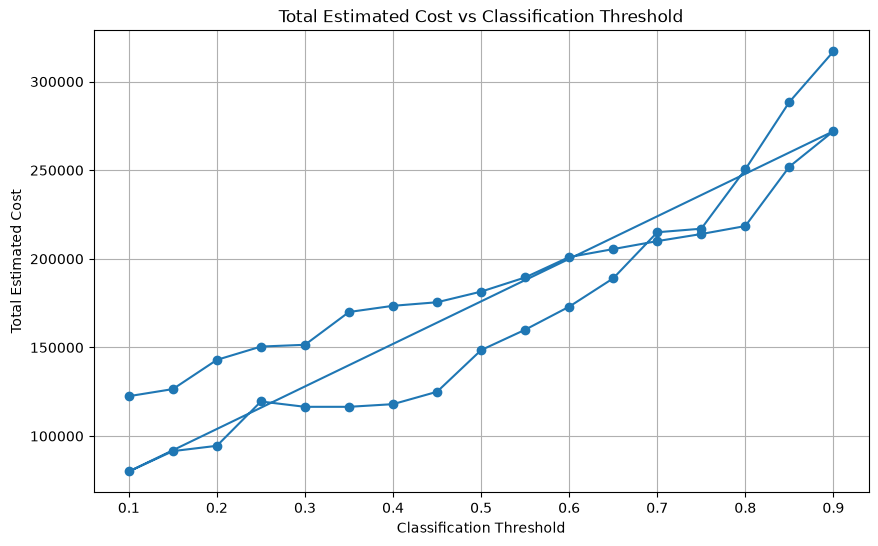

In [74]:
# ============================================================
# COST VS THRESHOLD
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Total Estimated Cost"],
    marker="o"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Total Estimated Cost")
plt.title("Total Estimated Cost vs Classification Threshold")

plt.grid(True)
plt.show()

In [75]:
# ============================================================
# PREDICTION FUNCTION
# ============================================================

def prepare_customer_data(customer_data):

    customer_data = customer_data.copy()

    # Convert Signup_Date
    if "Signup_Date" in customer_data.columns:
        customer_data["Signup_Date"] = pd.to_datetime(
            customer_data["Signup_Date"],
            errors="coerce"
        )

        # Create same date features used during training
        customer_data["Signup_Year"] = customer_data["Signup_Date"].dt.year
        customer_data["Signup_Month"] = customer_data["Signup_Date"].dt.month
        customer_data["Signup_Quarter"] = customer_data["Signup_Date"].dt.quarter
        customer_data["Signup_DayOfWeek"] = customer_data["Signup_Date"].dt.dayofweek

        # Remove original date
        customer_data = customer_data.drop(columns=["Signup_Date"])

    # Remove Customer_ID if present
    if "Customer_ID" in customer_data.columns:
        customer_data = customer_data.drop(columns=["Customer_ID"])

    # Same feature engineering used during training
    customer_data["Avg_Monthly_Total_Charges"] = (
        customer_data["Total_Charges"] /
        customer_data["Tenure_Months"].replace(0, 1)
    )

    customer_data["Charge_Ratio"] = (
        customer_data["Monthly_Charges"] /
        customer_data["Avg_Monthly_Total_Charges"].replace(0, 1)
    )

    customer_data["Activity_Risk"] = (
        customer_data["Days_Since_Last_Activity"] /
        customer_data["Tenure_Months"].replace(0, 1)
    )

    customer_data["Service_Issue_Score"] = (
        customer_data["Complaint_Count"] +
        customer_data["Support_Tickets_Raised"]
    )

    return customer_data

In [76]:
# ============================================================
# TEST CUSTOMER
# ============================================================

new_customer = X.iloc[[0]].copy()

new_customer

,Age,Gender,City,Income_Level,Tenure_Months,Contract_Type,Plan_Type,Payment_Method,Auto_Renewal_Flag,Usage_Frequency,...,Upsell_Downgrade_History,Email_Open_Rate_Pct,Signup_Year,Signup_Month,Signup_Quarter,Signup_DayOfWeek,Avg_Monthly_Total_Charges,Charge_Ratio,Activity_Risk,Service_Issue_Score
0,38,Male,Delhi,High,7,Annual,Basic,UPI,1,28,...,No History,5.9,2026,1,1,0,293.364286,1.03622,18.428571,0


In [77]:
# Prepare customer data
new_customer_prepared = prepare_customer_data(new_customer)

# Apply the same preprocessing
new_customer_processed = preprocessor.transform(
    new_customer_prepared
)

# Predict churn probability
churn_probability = final_model.predict_proba(
    new_customer_processed
)[:, 1][0]

# Predict churn class using validation-selected threshold
churn_prediction = int(
    churn_probability >= BEST_THRESHOLD
)

print("Churn Probability:", round(churn_probability, 4))
print("Churn Percentage:", round(churn_probability * 100, 2), "%")

if churn_prediction == 1:
    print("Prediction: CUSTOMER MAY CHURN")
else:
    print("Prediction: CUSTOMER MAY NOT CHURN")

Churn Probability: 0.2172
Churn Percentage: 21.72 %
Prediction: CUSTOMER MAY NOT CHURN


In [78]:
# FEATURE IMPORTANCE
# ============================================================
# Get the XGBoost model
#xgb_model = models_dict["XGBoost"]
xgb_model = final_model

# Get feature importance
importance = xgb_model.feature_importances_

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Create DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print("========== TOP 15 IMPORTANT FEATURES ==========")

display(feature_importance_df.head(15))

========== TOP 15 IMPORTANT FEATURES ==========


,Feature,Importance
12,numerical__Complaint_Count,0.202393
23,numerical__Charge_Ratio,0.058146
10,numerical__Late_Payment_Count,0.050231
16,numerical__Loyalty_Program_Member,0.037201
24,numerical__Activity_Risk,0.036372
39,categorical__Contract_Type_Annual,0.025969
4,numerical__Days_Since_Last_Activity,0.024399
14,numerical__Satisfaction_Score,0.021689
8,numerical__Total_Charges,0.020568
40,categorical__Contract_Type_Monthly,0.020454


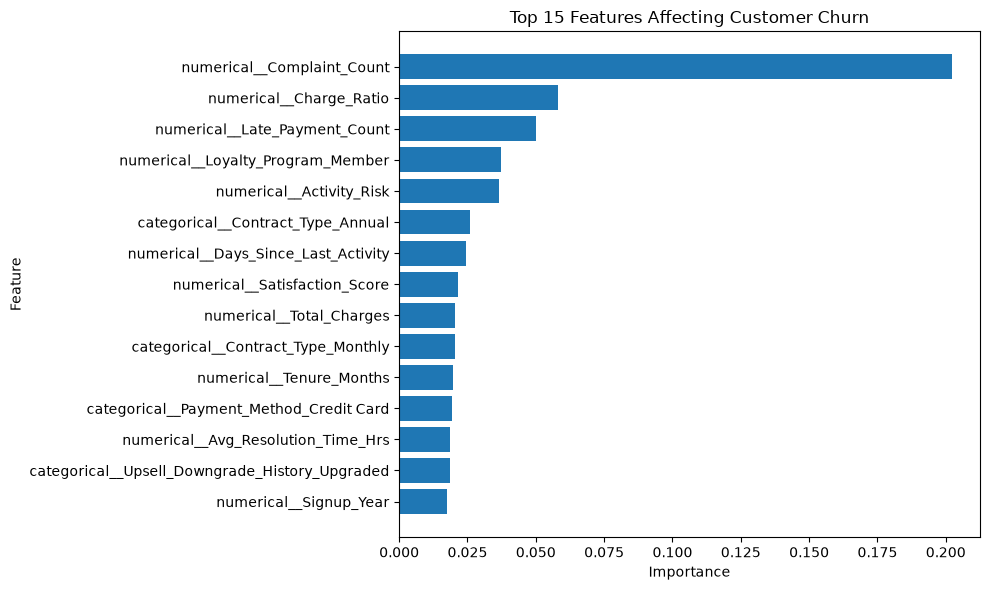

In [79]:
# Plot top 15 features

top_features = feature_importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Affecting Customer Churn")

plt.tight_layout()
plt.show()

In [80]:
print(models_dict.keys())

dict_keys(['Logistic Regression', 'Random Forest', 'XGBoost', 'Tuned XGBoost'])


In [81]:
# ============================================================
# SHAP ANALYSIS
# ============================================================

import shap
# ============================================================
# CREATE SHAP EXPLAINER
# ============================================================

# Get the XGBoost model
#xgb_model = models_dict["XGBoost"]
xgb_model = final_model

# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_processed)

print("SHAP analysis completed successfully.")


SHAP analysis completed successfully.


In [82]:
# ============================================================
# PREPARE DATA FOR SHAP VISUALIZATION
# ============================================================

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Convert processed test data into DataFrame
X_test_shap = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

print("SHAP visualization data prepared successfully.")
print("Number of features:", len(feature_names))

SHAP visualization data prepared successfully.
Number of features: 53


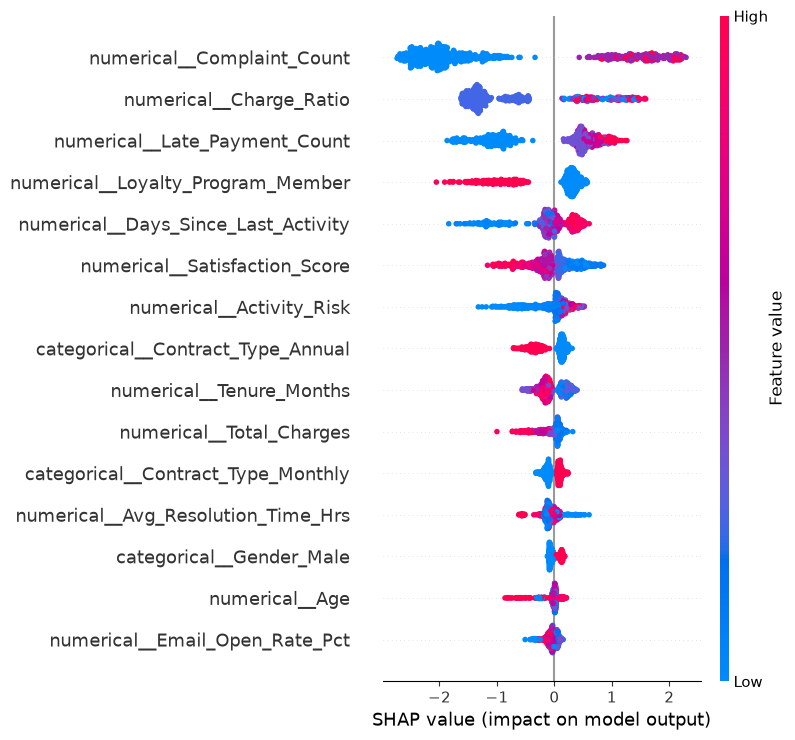

In [83]:
# ============================================================
# SHAP SUMMARY PLOT
# ============================================================

shap.summary_plot(
    shap_values,
    X_test_shap,
    max_display=15
)

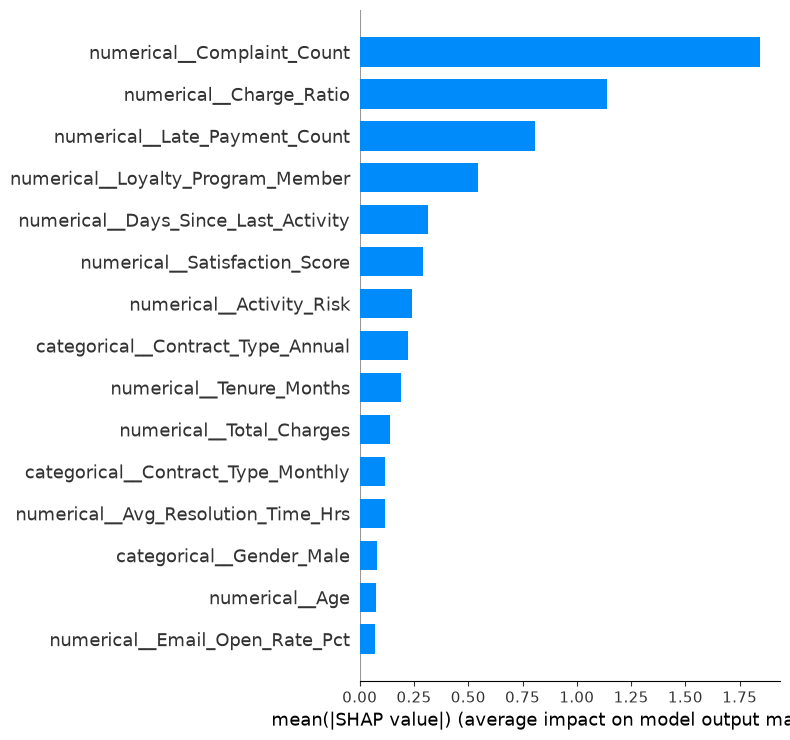

In [84]:
# ============================================================
# SHAP FEATURE IMPORTANCE - BAR PLOT
# ============================================================

shap.summary_plot(
    shap_values,
    X_test_shap,
    plot_type="bar",
    max_display=15
)

In [85]:
# ============================================================
# INDIVIDUAL CUSTOMER SHAP EXPLANATION
# ============================================================

# Select the first customer from the test dataset
customer_index = 0

customer_data = X_test_shap.iloc[[customer_index]]

print("Customer selected for SHAP explanation.")
print(customer_data)

Customer selected for SHAP explanation.
   numerical__Age  numerical__Tenure_Months  numerical__Auto_Renewal_Flag  \
0        1.055385                 -0.111545                      0.804556   

   numerical__Usage_Frequency  numerical__Days_Since_Last_Activity  \
0                    1.144489                             1.454271   

   numerical__Feature_Usage_Count  numerical__Avg_Session_Duration_Min  \
0                        0.236773                             0.939569   

   numerical__Monthly_Charges  numerical__Total_Charges  \
0                    1.268558                  0.624264   

   numerical__Discount_Applied_Pct  ...  categorical__Plan_Type_Premium  \
0                          1.79843  ...                             1.0   

   categorical__Plan_Type_Standard  categorical__Payment_Method_Credit Card  \
0                              0.0                                      0.0   

   categorical__Payment_Method_Debit Card  \
0                                     0.0

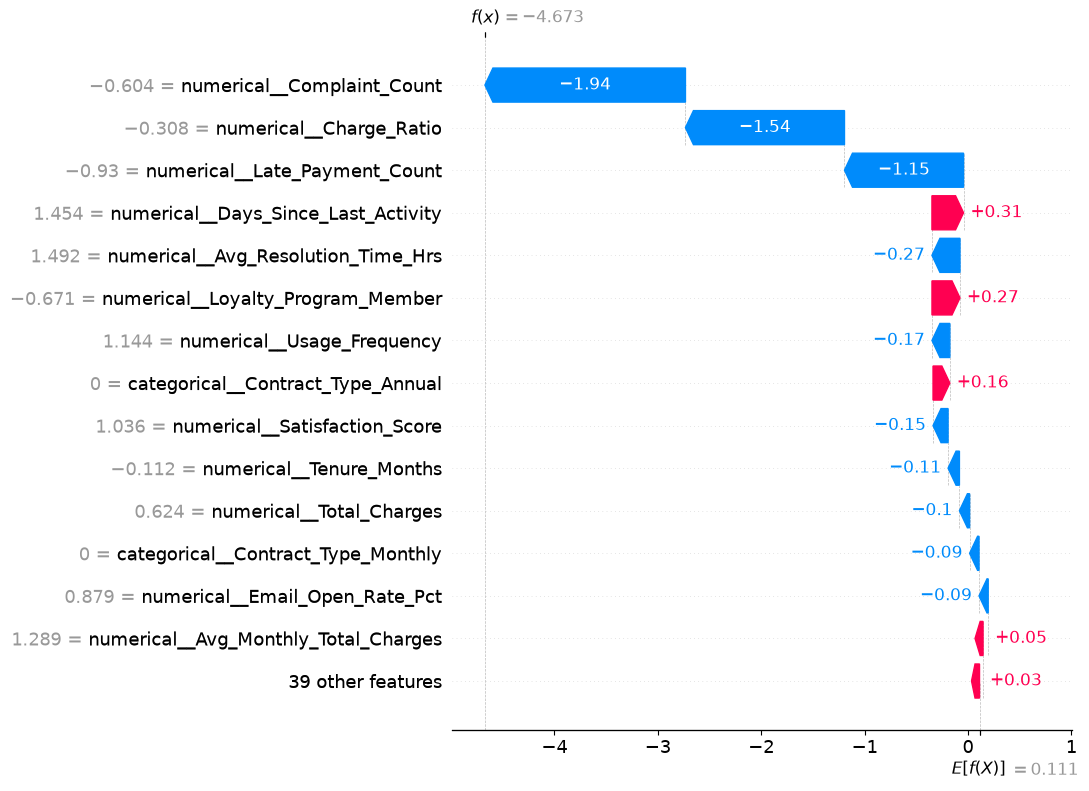

In [86]:
# ============================================================
# SHAP WATERFALL PLOT
# ============================================================

# Create SHAP explanation with actual feature names
shap_explanation = shap.Explanation(
    values=shap_values[customer_index],
    base_values=explainer.expected_value,
    data=X_test_shap.iloc[customer_index].values,
    feature_names=X_test_shap.columns.tolist()
)

# Display explanation
shap.plots.waterfall(
    shap_explanation,
    max_display=15
)

In [87]:
# ============================================================
# SHAP PREDICTION CONSISTENCY CHECK
# ============================================================

import numpy as np

shap_raw_output = explainer(
    X_test_processed[customer_index:customer_index + 1]
).values.sum() + explainer.expected_value

shap_probability = 1 / (1 + np.exp(-shap_raw_output))

model_probability = final_model.predict_proba(
    X_test_processed[customer_index:customer_index + 1]
)[0, 1]

print("SHAP raw output          :", shap_raw_output)
print("SHAP probability         :", shap_probability)
print("Model probability        :", model_probability)
print("Stored churn probability:", churn_probability)

SHAP raw output          : -4.6725454
SHAP probability         : 0.009261859
Model probability        : 0.009261847
Stored churn probability: 0.21719597


In [88]:
# ============================================================
# FINAL MODEL SUMMARY
# ============================================================

final_xgb = final_model

# Use the SAME test probabilities and predictions
# from the FINAL TEST SET EVALUATION
#y_prob_final = y_prob_test
#y_pred_final = y_pred_test
y_prob_final = y_test_prob
y_pred_final = y_test_pred

print("=" * 60)
print("FINAL XGBOOST MODEL SUMMARY")
print("=" * 60)

print("Model     :", FINAL_MODEL_NAME)
print("Threshold :", BEST_THRESHOLD)

print("Accuracy  :", round(
    accuracy_score(y_test, y_pred_final), 4
))

print("Precision :", round(
    precision_score(y_test, y_pred_final, zero_division=0), 4
))

print("Recall    :", round(
    recall_score(y_test, y_pred_final, zero_division=0), 4
))

print("F1 Score  :", round(
    f1_score(y_test, y_pred_final, zero_division=0), 4
))

print("ROC-AUC   :", round(
    roc_auc_score(y_test, y_prob_final), 4
))

print("PR-AUC    :", round(
    average_precision_score(y_test, y_prob_final), 4
))

print("Log Loss  :", round(
    log_loss(y_test, y_prob_final), 4
))

print("Brier     :", round(
    brier_score_loss(y_test, y_prob_final), 4
))

print("=" * 60)

FINAL XGBOOST MODEL SUMMARY
Model     : Tuned XGBoost
Threshold : 0.55
Accuracy  : 0.9177
Precision : 0.7217
Recall    : 0.7981
F1 Score  : 0.758
ROC-AUC   : 0.9517
PR-AUC    : 0.8037
Log Loss  : 0.219
Brier     : 0.0654


Confusion Matrix:
[[508  32]
 [ 21  83]]


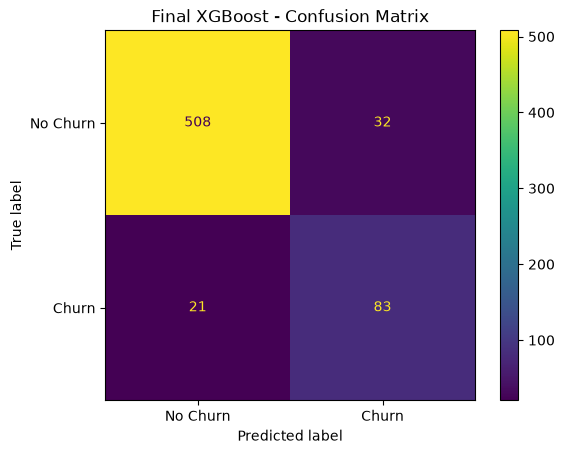

In [89]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_final)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Final XGBoost - Confusion Matrix")
plt.show()

In [90]:
from sklearn.metrics import classification_report

print("FINAL XGBOOST CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred_final,
    target_names=["No Churn", "Churn"],
    digits=4
))

FINAL XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn     0.9603    0.9407    0.9504       540
       Churn     0.7217    0.7981    0.7580       104

    accuracy                         0.9177       644
   macro avg     0.8410    0.8694    0.8542       644
weighted avg     0.9218    0.9177    0.9193       644



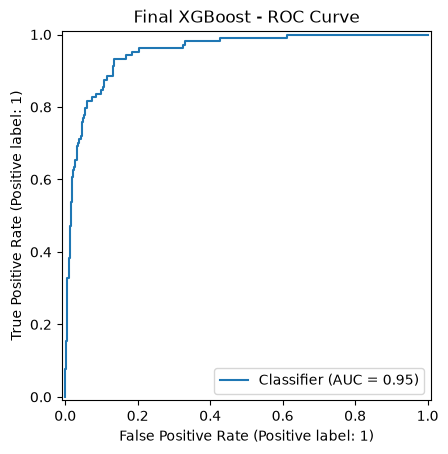

In [91]:
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_final
)

plt.title("Final XGBoost - ROC Curve")
plt.show()

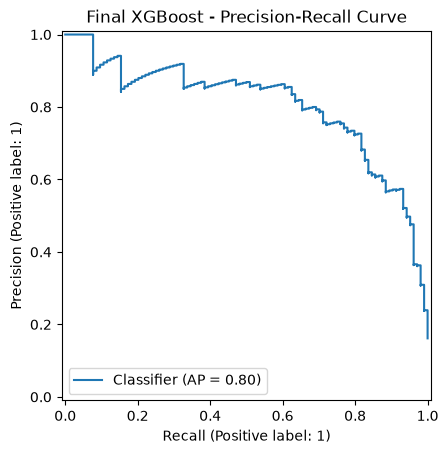

In [92]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_final
)

plt.title("Final XGBoost - Precision-Recall Curve")
plt.show()

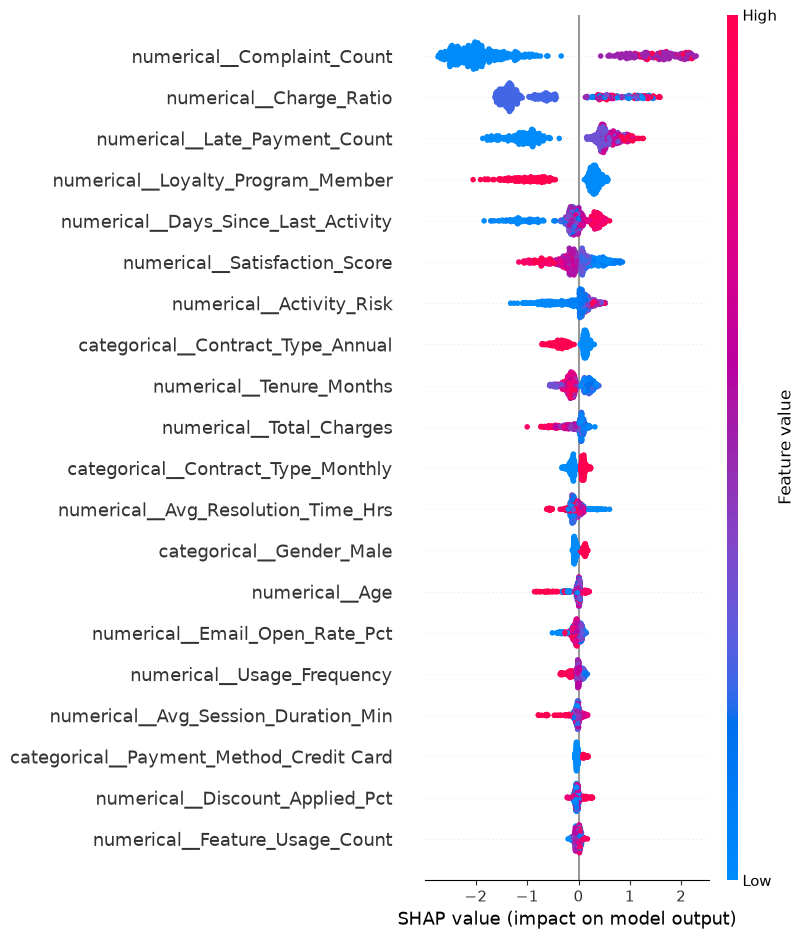

In [93]:
import shap

explainer = shap.TreeExplainer(final_model)

shap_values = explainer.shap_values(
    X_test_processed
)

shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names
)

In [94]:
# ============================================================
# SAVE FINAL MODEL AND PREPROCESSOR
# ============================================================

import os
import joblib

# Make sure the models folder exists
os.makedirs("models", exist_ok=True)

# Save final XGBoost model
joblib.dump(
    final_model,
    "models/final_xgboost_model.pkl"
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "models/preprocessor.pkl"
)

# Save classification threshold
joblib.dump(
    BEST_THRESHOLD,
    "models/best_threshold.pkl"
)

print("=" * 70)
print("MODEL ARTIFACTS SAVED")
print("=" * 70)

print("Final Model   : models/final_xgboost_model.pkl")
print("Preprocessor  : models/preprocessor.pkl")
print("Threshold     : models/best_threshold.pkl")

MODEL ARTIFACTS SAVED
Final Model   : models/final_xgboost_model.pkl
Preprocessor  : models/preprocessor.pkl
Threshold     : models/best_threshold.pkl


In [95]:
# ============================================================
# VERIFY SAVED MODEL ARTIFACTS
# ============================================================

import joblib
import os

# Load saved artifacts
loaded_model = joblib.load("models/final_xgboost_model.pkl")
loaded_preprocessor = joblib.load("models/preprocessor.pkl")
loaded_threshold = joblib.load("models/best_threshold.pkl")

print("=" * 70)
print("SAVED MODEL VERIFICATION")
print("=" * 70)

print("Model loaded       :", type(loaded_model).__name__)
print("Preprocessor loaded:", type(loaded_preprocessor).__name__)
print("Threshold loaded   :", loaded_threshold)

print("\nFiles exist:")
print("Model       :", os.path.exists("models/final_xgboost_model.pkl"))
print("Preprocessor:", os.path.exists("models/preprocessor.pkl"))
print("Threshold   :", os.path.exists("models/best_threshold.pkl"))

SAVED MODEL VERIFICATION
Model loaded       : XGBClassifier
Preprocessor loaded: ColumnTransformer
Threshold loaded   : 0.55

Files exist:
Model       : True
Preprocessor: True
Threshold   : True


In [96]:
# ============================================================
# NEXT STEP: PREDICT CHURN FOR A NEW CUSTOMER
# ============================================================

import pandas as pd
import joblib

# Load saved artifacts
model = joblib.load("models/final_xgboost_model.pkl")
preprocessor = joblib.load("models/preprocessor.pkl")
threshold = joblib.load("models/best_threshold.pkl")

print("Model loaded successfully")
print("Threshold:", threshold)

Model loaded successfully
Threshold: 0.55


In [97]:
def predict_customer_churn(customer_data):

    # Convert input into DataFrame
    customer_df = pd.DataFrame([customer_data])

    # Apply the same preprocessing used during training
    X_processed = preprocessor.transform(customer_df)

    # Get probability of churn
    churn_probability = model.predict_proba(X_processed)[:, 1][0]

    # Apply saved threshold
    prediction = int(churn_probability >= threshold)

    # Assign risk level
    if churn_probability >= 0.70:
        risk_level = "High Risk"
    elif churn_probability >= 0.40:
        risk_level = "Medium Risk"
    else:
        risk_level = "Low Risk"

    return {
        "Churn Probability": round(churn_probability, 4),
        "Prediction": "Will Churn" if prediction == 1 else "Will Not Churn",
        "Risk Level": risk_level
    }

In [98]:
sample_customer = X_test.iloc[0].to_dict()

result = predict_customer_churn(sample_customer)

print(result)

{'Churn Probability': np.float32(0.0093), 'Prediction': 'Will Not Churn', 'Risk Level': 'Low Risk'}
